# Análise exploratória de dados: Futebol Feminino Internacional (1956-2026)

**Por que esse tema?**

Em 2027, o Brasil vai sediar pela primeira vez uma Copa do Mundo Feminina FIFA — um marco histórico, já que é a primeira vez que a América do Sul recebe o torneio. Os jogos acontecem entre 24 de junho e 25 de julho de 2027, espalhados por 8 cidades brasileiras (Belo Horizonte, Brasília, Fortaleza, Porto Alegre, Recife, Rio de Janeiro, Salvador e São Paulo).

Acompanhei apenas as duas últimas edições da Copa do Mundo Feminina, e acompanho esporadicamente os campeonatos femininos nacionais, mas meu conhecimento sobre o cenário internacional do esporte sempre foi limitado — conheço um pouco sobre seleções como os Estados Unidos, e a Suécia. A notícia de que o Brasil vai sediar o Mundial em 2027 foi a motivação que faltava para mudar isso.

Este projeto nasce dessa vontade de conhecer melhor o futebol feminino fora do Brasil e aprofundar o conhecimento sobre o histórico e a trajetória de diferentes seleções pelo mundo. Antes da bola rolar em casa, quero entender: quais seleções dominam o cenário mundial, como o esporte evoluiu historicamente, e o que os números revelam sobre países que talvez a gente nunca tenha ouvido falar.

**Fonte dos dados:** [Women's International Football Results (Kaggle)](https://www.kaggle.com/datasets/martj42/womens-international-football-results?resource=download), com mais de 11 mil partidas internacionais femininas desde 1956.

**Perguntas de análise a serem respondidas:**
1. Quais seleções dominam o cenário internacional?
2. Fora do radar: quais seleções além das tradicionais chamam atenção?
3. Como foi a evolução das principais seleções nas Copas do Mundo?
4. Como o número de jogos e seleções participantes evoluiu ao longo do tempo?
5. O nível de jogo (aferido por gols e goleadas) mudou ao longo das edições da Copa do Mundo? As edições mais recentes são mais disputadas ou mais desiguais?
6. Jogar em casa é uma vantagem real no futebol feminino?


### Carregamento dos Dados

Leitura de `data/results_limpo.csv` (gerado por `_limpeza.ipynb`, onde ficaram a inspeção estrutural e as verificações de nulos, duplicatas e tipos), com `date` já convertida para datetime. O `assert` confere que o arquivo é o esperado: 11.650 partidas, 244 seleções e 118 torneios.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import permutations
import seaborn as sns

from config import NAO_COMPETITIVOS, TORNEIOS_CONFEDERACAO

In [37]:
resultados = pd.read_csv('data/results_limpo.csv', parse_dates=['date'])

# Conferência: este deve ser o arquivo gerado por _limpeza.ipynb
n_selecoes = pd.concat([resultados['home_team'], resultados['away_team']]).nunique()
assert (len(resultados), n_selecoes, resultados['tournament'].nunique()) == (11650, 244, 118), \
    'results_limpo.csv inesperado: rode _limpeza.ipynb antes'

### Limpeza dos dados

A limpeza foi feita em [`_limpeza.ipynb`](_limpeza.ipynb), que gera `data/results_limpo.csv` e `data/shootouts_limpo.csv`. Resumo das decisões:

| Etapa | Decisão |
|---|---|
| Nulos e duplicatas | Nenhum encontrado |
| Nomes de seleções | 4 pares unificados (Shetland, Hitra, Turks and Caicos, U.S. Virgin Islands): 248 → 244 seleções |
| Nomes de torneios | 3 erros de digitação/plural corrigidos e `World Cup` renomeado para `World Cup (pre-FIFA)` (jogos de 1970–71): 121 → 118 torneios |
| Placares | Entre os maiores placares, 5 foram confirmados na RSSSF e 10 mantidos sem verificação externa. Corrigidos Camarões x África do Sul (2006), de 2x24 para 2x2, e Polônia x Rússia (2011), de 0-20 para 0-2 |
| Datas | 4 partidas do OFC Championship de 1998 estavam datadas em dezembro e foram corrigidas para outubro |
| Integridade | Nenhuma seleção jogando contra si mesma. Os times com 2 jogos no mesmo dia (3 entidades CONIFA, Jamaica e África do Sul) foram mantidos, sem verificação externa |
| CONIFA | Mantidas, com a coluna `fifa_affiliated` para filtrar quando necessário |
| Pênaltis | Mesma unificação de nomes; o vencedor é sempre uma das duas seleções e as 136 disputas têm partida correspondente em `resultados` |

`is_competitive` e as demais colunas derivadas não fazem parte da limpeza e são criadas na próxima seção.

### Preparação para a análise - feature engineering

Transformação dos dados em variáveis relevantes antes de seguir para a análise exploratória.

In [38]:
# Criação de colunas derivadas
resultados['year'] = resultados['date'].dt.year
resultados['decade'] = (resultados['year'] // 10) * 10
resultados['total_goals'] = resultados['home_score'] + resultados['away_score']
resultados['goal_difference'] = resultados['home_score'] - resultados['away_score']
resultados['match_outcome'] = np.select(
    [resultados['home_score'] > resultados['away_score'],
     resultados['home_score'] < resultados['away_score']],
    ['home_win', 'away_win'],
    default='draw'
)
resultados['match_id'] = resultados.index

In [39]:
resultados['is_competitive'] = ~resultados['tournament'].isin(NAO_COMPETITIVOS)
print(resultados['is_competitive'].value_counts())

is_competitive
True     8686
False    2964
Name: count, dtype: int64


**Flag `is_competitive`**

`False` para amistosos avulsos e torneios por convite (Algarve Cup, SheBelieves Cup, Tournament of Nations etc.); `True` para as demais competições. São 2.964 jogos não competitivos (~25% do total). Classificação por exclusão, com lista revisada manualmente; casos ambíguos (torneios regionais e jogos multiesportivos) ficaram como competitivos. Nenhum dado removido: a flag permite comparar métricas com e sem esses jogos.

A lista de torneios não competitivos fica em `config.py` (`NAO_COMPETITIVOS`), para poder ser ajustada sem refazer a limpeza.


In [40]:
# Criação de uma tabela derivada
# Separação das informações das seleções de cada jogo em duas linhas em vez de uma
# aplicação do formato long, informações verticais

colunas_base = ['match_id', 'date', 'year', 'tournament', 'neutral', 'is_competitive', 'fifa_affiliated']

home = resultados[colunas_base + ['home_team', 'home_score', 'away_score']].copy()
home.columns = colunas_base + ['team', 'goals_for', 'goals_against']
home['venue'] = 'home'

away = resultados[colunas_base + ['away_team', 'away_score', 'home_score']].copy()
away.columns = colunas_base + ['team', 'goals_for', 'goals_against']
away['venue'] = 'away'

matches_long = pd.concat([home, away], ignore_index=True)
matches_long['decade'] = (matches_long['date'].dt.year // 10) * 10
matches_long['outcome'] = np.select(
    [matches_long['goals_for'] > matches_long['goals_against'],
     matches_long['goals_for'] < matches_long['goals_against']],
    ['win', 'loss'], default='draw'
)
matches_long['points'] = matches_long['outcome'].map({'win': 3, 'draw': 1, 'loss': 0})
matches_long['goal_difference'] = matches_long['goals_for'] - matches_long['goals_against']

# Ordena a tabela toda com base no ID do jogo
matches_long = matches_long.sort_values('match_id').reset_index(drop=True)

# Cada partida vira duas linhas (uma por seleção)
assert len(matches_long) == 2 * len(resultados)

#### Feature engineering: colunas derivadas e formato long

**Colunas derivadas em `resultados`:** `year`, `decade`, `total_goals`, `goal_difference`, `match_outcome` (`home_win`/`away_win`/`draw`) e `match_id`.

**`matches_long`:** uma linha por seleção por partida, com `team`, `goals_for`, `goals_against`, `venue` (`home`/`away`) e `outcome` (`win`/`loss`/`draw`, do ponto de vista de cada time), ordenada por `match_id`.

**Por que manter os dois formatos:**
- `resultados` (wide): perguntas sobre o *evento da partida* (ex.: vitórias de mandantes vs. visitantes, média de gols)
- `matches_long` (long): perguntas sobre a *trajetória de uma seleção* (ex.: ranking de vitórias, desempenho do Brasil ano a ano)

### Premissas e limitações gerais

Valem para as Perguntas 1 a 3; cada seção traz depois só as limitações específicas.

- **Adversários não ponderados:** vencer uma seleção fraca vale os mesmos 3 pontos que vencer uma potência, o que favorece quem joga contra oponentes mais fracos na própria confederação (ex.: Coreia do Norte, Vietnã, África do Sul). Extensão possível: rating tipo Elo
- **Década de 2020 parcial:** dados até jun/2026, menos de 7 anos contra 10 das demais
- **`is_competitive` é subjetiva:** classificação por exclusão com revisão manual; casos ambíguos ficaram como competitivos
- **CONIFA e regionais mantidos:** marcados em `fifa_affiliated` e praticamente fora dos rankings pelo `MIN_JOGOS`
- **Parâmetros são escolhas de regra:** `MIN_JOGOS`, `MIN_JOGOS_JANELA`, corte do top N e limiar de ascensão; sensibilidade testada onde fazia diferença
- **Cobertura desigual:** o dataset é colaborativo, e as décadas antigas têm poucas seleções e jogos documentados, enquanto os amistosos recentes aparecem em volume muito maior; contagens de jogos e seleções ao longo do tempo (Q4) misturam crescimento real e cobertura melhor
- **Três medidas de variação, não comparáveis entre si:** a 1.3 compara décadas (1990s a 2020s\*) em jogos competitivos de todos os torneios; a 1.5 e a Q2 usam o recorte 2010s → 2020s\* nesses mesmos jogos; e a Q3 compara eras de Copa (1991–1999, 2003–2011, 2015–2023), só com jogos da Copa do Mundo. O Brasil ilustra a diferença: perde aproveitamento competitivo em 2020s\* (−9,0 pp, 1.5), tem alta em Copas contra 1991–1999 (+10,4 pp, Q3) e queda contra 2003–2011 (−18,6 pp, Q3), o que é coerente com um recuo recente

### 1. Quais seleções dominam o cenário internacional?


##### 1.1 Histórico e consolidação

Análise dos títulos, vices e participações em Copas do Mundo FIFA (1991–2023). A lógica identifica o campeão e o vice de cada edição pelo placar do tempo regulamentar ou, em caso de empate, pelos pênaltis. Os títulos ficam restritos à Copa do Mundo, porque a mesma lógica falha em torneios com fase de pontos corridos e sem final (Eurocopa e Copa América).

In [41]:
# Carregamento dos pênaltis (já limpos: nomes de seleções unificados em _limpeza.ipynb)
penaltis = pd.read_csv('data/shootouts_limpo.csv', parse_dates=['date'])

In [42]:
# Função para calcular campeãs e vices da Copa do Mundo
def calculo_campeoes(nome_torneio, resultados, penaltis):
    torneio_df = resultados[resultados['tournament'] == nome_torneio].copy()
    torneio_df = torneio_df.sort_values('date')

    finais = torneio_df.groupby('year').tail(1)
    lista_campeos = []

    for _, row in finais.iterrows():
        home, away = row['home_team'], row['away_team']
        h_score, a_score = row['home_score'], row['away_score']
        match_date = row['date']

        if h_score > a_score:
            campeao, vice = home, away
        elif h_score < a_score:
            campeao, vice = away, home
        else:
            resultado_penaltis = penaltis[
                (penaltis['date'] == match_date) & ((penaltis['home_team'] == home) | (penaltis['away_team'] == home))]

            if not resultado_penaltis.empty:
                vencedor_penal = resultado_penaltis['winner'].values[0]
                campeao = vencedor_penal
                vice = away if vencedor_penal == home else home
            else:
                campeao, vice = "Empate (Sem registro de pênaltis)", "Empate (Sem registro de pênaltis)"

        g_camp, g_vice = (h_score, a_score) if campeao == home else (a_score, h_score)
        lista_campeos.append({
            'year': row['year'], 'date': match_date,
            'champion': campeao, 'runner_up': vice,
            'score': f"{g_camp} - {g_vice}"
        })
    return pd.DataFrame(lista_campeos)

In [43]:
# Tabela histórica (Participações, Títulos e Vices)
campeoes_copa = calculo_campeoes('FIFA World Cup', resultados, penaltis)

copas = resultados[resultados['tournament'] == 'FIFA World Cup']
participacoes = pd.concat([copas[['year', 'home_team']].rename(columns={'home_team': 'team'}),
                  copas[['year', 'away_team']].rename(columns={'away_team': 'team'})]).drop_duplicates().groupby('team').size().rename('Participações')

titulos = campeoes_copa['champion'].value_counts().rename('Títulos')
vices = campeoes_copa['runner_up'].value_counts().rename('Vices')

anos_titulos = campeoes_copa.groupby('champion')['year'].apply(lambda x: ', '.join(map(str, sorted(x)))).rename('Anos dos Títulos')
anos_vices = campeoes_copa.groupby('runner_up')['year'].apply(lambda x: ', '.join(map(str, sorted(x)))).rename('Anos dos Vices')

historico = pd.concat([participacoes, titulos, vices, anos_titulos, anos_vices], axis=1).fillna({
    'Participações': 0, 'Títulos': 0, 'Vices': 0, 'Anos dos Títulos': '', 'Anos dos Vices': ''
}).astype({'Participações': int, 'Títulos': int, 'Vices': int}).rename_axis('Seleção').reset_index().sort_values(['Títulos', 'Vices', 'Participações'], ascending=False).reset_index(drop=True)

print(f"{len(historico)} seleções já disputaram a Copa do Mundo")
display(historico.head(15))

44 seleções já disputaram a Copa do Mundo


,Seleção,Participações,Títulos,Vices,Anos dos Títulos,Anos dos Vices
0,United States,9,4,1,"1991, 1999, 2015, 2019",2011
1,Germany,9,2,1,"2003, 2007",1995
2,Japan,9,1,1,2011,2015
3,Norway,9,1,1,1995,1991
4,Spain,3,1,0,2023,
5,Brazil,9,0,1,,2007
6,Sweden,9,0,1,,2003
7,China,8,0,1,,1999
8,England,6,0,1,,2023
9,Netherlands,3,0,1,,2019


**Conclusões**

`calculo_campeoes()` identificou campeã e vice nas 9 edições, e `historico` consolidou títulos, vices e participações por seleção. Ao todo, **44 seleções** já disputaram a Copa.

- O topo é concentrado: só 5 seleções foram campeãs e 10 chegaram a uma final, entre 44 participantes
- Presença constante não garante final: Nigéria (9 participações), Austrália (8) e Canadá (8) estão entre as seleções mais frequentes e nunca chegaram a uma final
- O Brasil e Suécia estiveram em todas as 9 edições e disputaram uma única final cada (Brasil em 2007, derrota por 2-0 para a Alemanha; Suécia em 2003, derrota por 2-1 para a Alemanha)
- Renovação recente: duas novas campeãs (Japão 2011, Espanha 2023) e uma nova finalista (Holanda 2019)

##### 1.2 Desempenho estatístico

Totais absolutos favorecem quem joga mais e torneios por convite inflam o calendário de algumas seleções, então o ranking usa **taxas por jogo** (aproveitamento, gols pró e saldo), com **mínimo de 100 partidas** (testado com 50 e 150).

São calculadas duas versões: todas as partidas e só as competitivas (`is_competitive`). A competitiva é a tabela de referência; a completa mede quanto o filtro muda o ranking e quanto do calendário de cada seleção vem de amistosos e torneios por convite.

**Limitação:** ver Premissas. Retirar os jogos não competitivos muda o tipo de adversário, não torna o ranking mais justo. Diferenças pequenas entre posições vizinhas não indicam superioridade real.

In [44]:
def desempenho(df, min_jogos=0):
    g = df.groupby('team').agg(
        Jogos=('match_id', 'count'),
        Vitórias=('outcome', lambda x: (x == 'win').sum()),
        Pontos=('points', 'sum'),
        Gols_pró=('goals_for', 'sum'),
        Gols_contra=('goals_against', 'sum'),
        Saldo=('goal_difference', 'sum')
    )
    g['Vitórias_%'] = 100 * g['Vitórias'] / g['Jogos']
    g['Aproveitamento_%'] = 100 * g['Pontos'] / (3 * g['Jogos'])
    g['Gols_pró_jogo'] = g['Gols_pró'] / g['Jogos']
    g['Saldo_jogo'] = g['Saldo'] / g['Jogos']
    
    if min_jogos > 0:
        g = g[g['Jogos'] >= min_jogos]
    return g.sort_values(['Aproveitamento_%', 'Saldo_jogo'], ascending=False)

def montar_ranking(min_jogos):
    todos = desempenho(matches_long, min_jogos=min_jogos)
    comp = desempenho(matches_long[matches_long['is_competitive']], min_jogos=min_jogos)
    
    comp['Rank_competitivo'] = range(1, len(comp) + 1)
    comp['Rank_todos'] = pd.Series(range(1, len(todos) + 1), index=todos.index).reindex(comp.index)
    comp['Jogos_todos'] = todos['Jogos'].reindex(comp.index)
    comp['Não_competitivo_%'] = 100 * (1 - comp['Jogos'] / comp['Jogos_todos'])
    return todos, comp

In [45]:
# Execução com limiar definido e cálculo da variação de ranking
MIN_JOGOS = 100
desemp_geral, desemp_oficial = montar_ranking(MIN_JOGOS)

rank_geral_filtrado = desemp_geral.loc[desemp_oficial.index].sort_values(['Aproveitamento_%', 'Saldo_jogo'], ascending=False)
desemp_oficial['Rank_Geral_Elegiveis'] = pd.Series(range(1, len(rank_geral_filtrado) + 1), index=rank_geral_filtrado.index).reindex(desemp_oficial.index)
desemp_oficial['Variação_rank'] = desemp_oficial['Rank_Geral_Elegiveis'] - desemp_oficial['Rank_competitivo']

# Sensibilidade ao mínimo de jogos: o top 10 muda com 50 ou 150?
top10_ref = list(desemp_oficial.index[:10])
top10_igual = all(list(montar_ranking(lim)[1].index[:10]) == top10_ref for lim in (50, 150))
print(f'Seleções elegíveis (≥ {MIN_JOGOS} jogos competitivos): {len(desemp_oficial)} | top 10 idêntico com mínimo de 50 e 150: {top10_igual}')

# Exibição do Top 10 comparativo
colunas_mov = ['Jogos', 'Não_competitivo_%', 'Aproveitamento_%', 'Rank_Geral_Elegiveis', 'Rank_competitivo', 'Variação_rank']
display(desemp_oficial[colunas_mov].sort_values('Rank_competitivo').head(10).round(2))

Seleções elegíveis (≥ 100 jogos competitivos): 66 | top 10 idêntico com mínimo de 50 e 150: True


,Jogos,Não_competitivo_%,Aproveitamento_%,Rank_Geral_Elegiveis,Rank_competitivo,Variação_rank
team,,,,,,
United States,167,72.17,87.43,1,1,0
Germany,307,28.27,79.26,2,2,0
Brazil,154,52.02,73.59,5,3,2
Sweden,328,32.79,70.02,6,4,2
North Korea,167,16.50,69.26,3,5,-2
France,251,32.71,69.06,4,6,-2
Norway,306,35.17,68.74,8,7,1
England,255,33.77,68.24,7,8,-1
China,241,49.26,67.63,17,9,8


**Conclusões**

Ranking por aproveitamento (pontos / 3 × jogos), com desempate por saldo de gols por jogo e mínimo de 100 jogos: **66 seleções** na versão competitiva (referência). O top 10 é idêntico com mínimo de 50, 100 e 150 jogos.

**Leitura:**
- **Estados Unidos isolados no topo**, 8 pp à frente da Alemanha, e também líderes com todas as partidas
- **Margens estreitas entre a 5ª e a 8ª posição** (0,2 a 0,5 pp): não dá para afirmar superioridade entre elas
- **O filtro mexe pouco no topo:** as 8 primeiras mudam no máximo 2 posições (Brasil e Suécia sobem 2; Coreia do Norte e França caem 2)
- **O peso dos jogos não competitivos varia muito:** 72% do calendário dos EUA, 52% do Brasil e 49% da China, contra 16,5% da Coreia do Norte
- **China é o maior movimento do top 10:** sobe da 17ª para a 9ª ao filtrar

##### 1.3 Cenário atual: quem está em ascensão

Trajetória do aproveitamento competitivo das finalistas de Copa (campeãs e vices, 1991 a 2023) por década, de 1990 a 2020. **Ascensão** = variação do aproveitamento (em pp) entre as décadas, só com partidas competitivas. Usa taxa, e não contagem de vitórias, porque a janela recente é mais curta, com mínimo de jogos por janela (`MIN_JOGOS_JANELA = 20`).

A década de 2020 é **parcial** (jan/2020 a jun/2026) e aparece como `2020s*`.

In [46]:
# Configurações e Parâmetros
anos_decadas = {
    "1990s": (1990, 1999),
    "2000s": (2000, 2009),
    "2010s": (2010, 2019),
    "2020s*": (2020, 2026),  # parcial: dados até jun/2026
}

MIN_JOGOS_JANELA = 20
LIMIAR_PP = 5.0   # variação mínima (pp) para "ascensão" (1.5) e "subiu/decaiu" (Q3)
rot_rec = "2020s*"

partidas_competitivas = matches_long[matches_long["is_competitive"]]
finalistas_copa = set(campeoes_copa["champion"]) | set(campeoes_copa["runner_up"])

# Funções Auxiliares
def aproveitamento_janela(sub_df, ini, fim, min_jogos=MIN_JOGOS_JANELA):
    """Aproveitamento percentual das seleções em uma janela de anos."""
    d = sub_df[sub_df["year"].between(ini, fim)]
    g = d.groupby("team").agg(Jogos=("match_id", "count"), Pontos=("points", "sum"))
    g["Aproveitamento_%"] = 100 * g["Pontos"] / (3 * g["Jogos"])
    return g[g["Jogos"] >= min_jogos][["Jogos", "Aproveitamento_%"]]

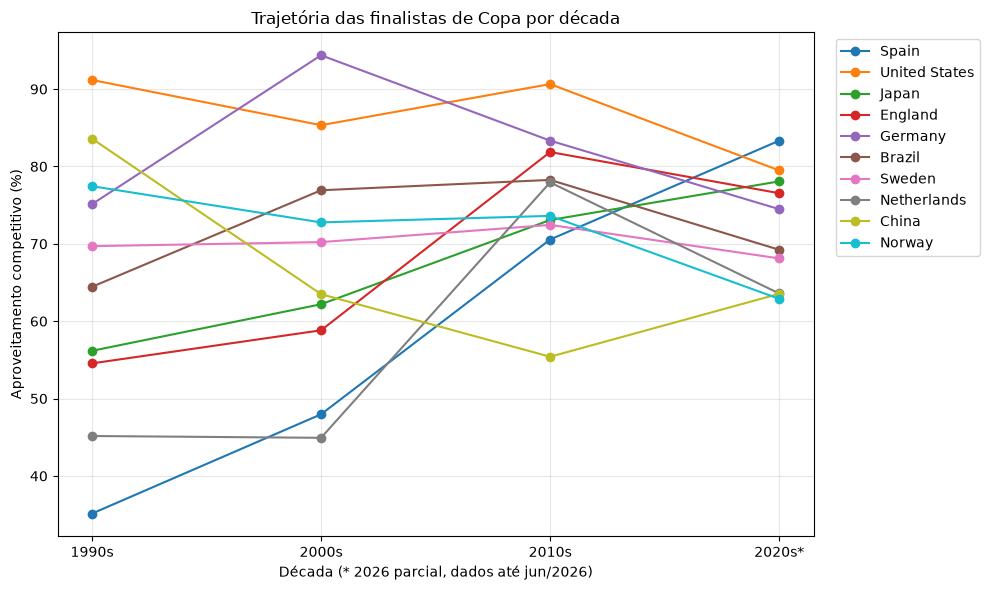

In [47]:
# Trajetória das Finalistas por Década e Plotagem do Gráfico
trajetoria = pd.DataFrame(
    {
        rot: aproveitamento_janela(partidas_competitivas, *anos)["Aproveitamento_%"]
        for rot, anos in anos_decadas.items()
    }
)
traj_fin = (
    trajetoria.loc[trajetoria.index.isin(finalistas_copa)]
    .dropna()
    .sort_values(rot_rec, ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))
for team, row in traj_fin.iterrows():
  ax.plot(traj_fin.columns, row.values, marker="o", label=team)

ax.set_ylabel("Aproveitamento competitivo (%)")
ax.set_xlabel("Década (* 2026 parcial, dados até jun/2026)")
ax.set_title("Trajetória das finalistas de Copa por década")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Conclusões**

- **Espanha é a maior ascensão:** de cerca de 35% nos anos 1990 para cerca de 83% em 2020s\*, o maior aproveitamento do grupo na década atual
- **Japão sobe a cada década** (de cerca de 56% para 78%), e a **China** se recupera após o fundo dos anos 2010
- **Quem domina o histórico recua em 2020s\*:** Estados Unidos e Alemanha caem, e Brasil, Suécia e Noruega também perdem aproveitamento (jogos competitivos de todos os torneios, ver Premissas sobre as três medidas de variação)
- **Inglaterra e Holanda** têm saltos nos anos 2010, mas a Holanda devolve boa parte deles em 2020s\*

Ressalvas gerais: ver Premissas.

##### 1.4 Confronto direto entre as principais

Confrontos diretos (V-E-D e gols) entre as 12 seleções do grupo (as 6 primeiras do ranking competitivo da 1.2 e todas as finalistas de Copa da 1.1), de 1956 em diante. A primeira tabela resume o desempenho do grupo nas partidas competitivas, com a posição no grupo e no ranking mundial; o segundo, um mapa de calor, mostra o saldo V − D de cada seleção contra cada outra (todas as partidas, com o Brasil contornado); e a terceira tabela detalha o Brasil contra cada adversário em dois recortes: só as competitivas e 2010 em diante.

In [48]:
N_GRUPO, DESDE = 6, 1956
GRUPO = desemp_oficial.head(N_GRUPO).index.tolist()
GRUPO += [t for t in finalistas_copa if t not in GRUPO]   # todas as finalistas (campeãs e vices)

# Adversário de cada linha de matches_long
adv = pd.concat([
    resultados[['match_id', 'away_team']].rename(columns={'away_team': 'opponent'}).assign(venue='home'),
    resultados[['match_id', 'home_team']].rename(columns={'home_team': 'opponent'}).assign(venue='away'),
])
matches_long = matches_long.drop(columns=['opponent'], errors='ignore').merge(adv, on=['match_id', 'venue'], how='left')

def confrontos(grupo, desde=1956, so_competitivos=False):
    b = matches_long[(matches_long['year'] >= desde) & matches_long['team'].isin(grupo)
                     & matches_long['opponent'].isin(grupo)]
    if so_competitivos:
        b = b[b['is_competitive']]
    b = b.assign(V=b['outcome'] == 'win', E=b['outcome'] == 'draw', D=b['outcome'] == 'loss')
    chave = ['team', 'opponent']
    g = b.groupby(chave)[['V', 'E', 'D', 'goals_for', 'goals_against']].sum()
    g.insert(0, 'jogos', b.groupby(chave).size())
    g = g.rename(columns={'goals_for': 'GP', 'goals_against': 'GC'})
    pares = pd.MultiIndex.from_tuples(list(permutations(grupo, 2)), names=chave)
    return g.reindex(pares, fill_value=0).astype(int)

In [49]:
# Resumo do grupo no confronto direto (só partidas competitivas, a base de referência da 1.2)
posicao_rank_competitivo = {t: i + 1 for i, t in enumerate(desemp_oficial.index)}

def resumo_grupo(t):
    r = t.groupby('team')[['jogos', 'V', 'E', 'D', 'GP', 'GC']].sum()
    r['Aproveit_%'] = 100 * (3 * r['V'] + r['E']) / (3 * r['jogos'])
    r['Saldo_jogo'] = (r['GP'] - r['GC']) / r['jogos']
    r = r.sort_values(['Aproveit_%', 'Saldo_jogo'], ascending=False)
    # empate em aproveitamento = mesma posição (o saldo só define a ordem de exibição)
    r['posicao_grupo'] = r['Aproveit_%'].round(6).rank(method='min', ascending=False).astype(int)
    return r

tab_jg_competitivos_grupo = resumo_grupo(confrontos(GRUPO, DESDE, True))

resumo = pd.DataFrame({
    'jogos': tab_jg_competitivos_grupo['jogos'],
    'Aproveit_%': tab_jg_competitivos_grupo['Aproveit_%'].round(1),
    'pos. grupo': tab_jg_competitivos_grupo['posicao_grupo'],
    'pos. mundial (1.2)': pd.Series(posicao_rank_competitivo).reindex(tab_jg_competitivos_grupo.index),
}).astype({'jogos': 'Int64', 'pos. grupo': 'Int64', 'pos. mundial (1.2)': 'Int64'})

print('--- Grupo no confronto direto, só partidas competitivas ---')
display(resumo)

--- Grupo no confronto direto, só partidas competitivas ---


,jogos,Aproveit_%,pos. grupo,pos. mundial (1.2)
team,,,,
United States,68,77.0,1,1
Germany,111,64.9,2,2
Norway,107,50.8,3,7
France,76,46.1,4,6
Sweden,115,44.3,5,4
Brazil,52,43.6,6,3
Japan,100,42.0,7,10
North Korea,67,41.8,8,5
England,91,39.2,9,8


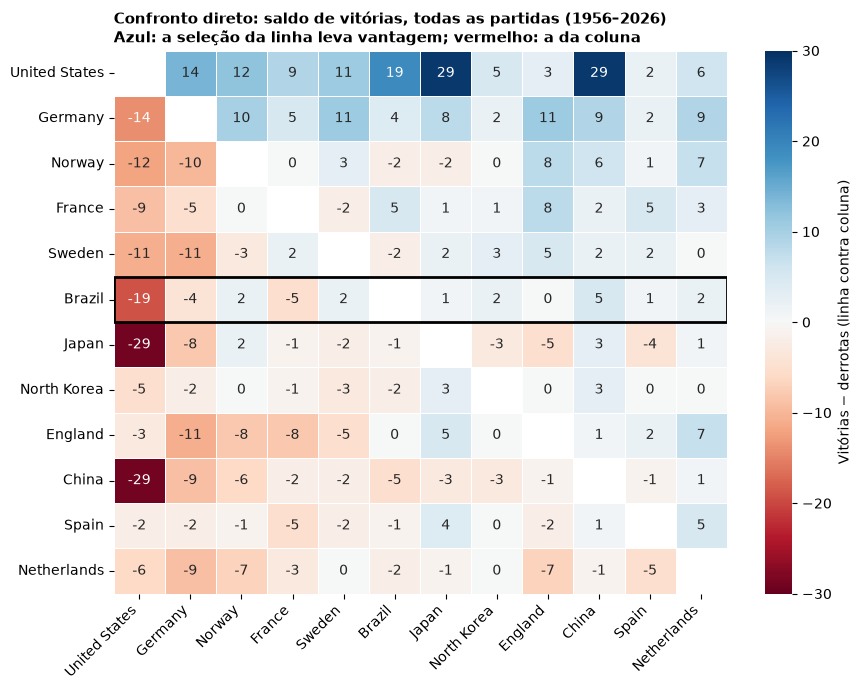

--- Brasil: só competitivas e 2010 em diante ---


comp.               2010+               
              jogos  V-E-D   gols jogos   V-E-D   gols
adversário                                            
United States    11  1-2-8   7-17    19  4-4-11  20-36
Germany           8  1-3-4  10-17     3   1-0-2    4-7
Sweden            7  4-1-2   10-5     4   2-1-1    8-4
North Korea       1  1-0-0    2-1     1   1-0-0    2-0
France            4  1-1-2    4-5     8   1-1-6   8-14
Norway            6  3-2-1   11-6     3   2-0-1    8-4
England           1  0-1-0    1-1     5   2-1-2    6-6
Spain             3  2-0-1    5-4     6   3-1-2    9-8
China             5  4-0-1   17-5     6   3-3-0   14-3
Japan             5  2-0-3    5-6    12   5-2-5  17-21
Netherlands       1  0-1-0    3-3     4   1-3-0    7-6

In [50]:
RECORTES = {'todos': (1956, False), 'comp.': (1956, True), '2010+': (2010, False)}
tabs = {nome: confrontos(GRUPO, d, c) for nome, (d, c) in RECORTES.items()}
ordem = tab_jg_competitivos_grupo.index   # mesma ordem da tabela anterior

def ved(t): return t['V'].astype(str) + '-' + t['E'].astype(str) + '-' + t['D'].astype(str)
def gols(t): return t['GP'].astype(str) + '-' + t['GC'].astype(str)

# Saldo V − D no confronto direto (linha contra coluna), todas as partidas
saldo = (tabs['todos']['V'] - tabs['todos']['D']).unstack().reindex(index=ordem, columns=ordem)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(saldo, annot=True, fmt='.0f', cmap='RdBu', center=0, vmin=-30, vmax=30, linewidths=0.5,
            linecolor='white', cbar_kws={'label': 'Vitórias − derrotas (linha contra coluna)'}, ax=ax)
ax.grid(False)
idx_br = list(ordem).index('Brazil')
ax.add_patch(plt.Rectangle((0, idx_br), len(ordem), 1, fill=False, edgecolor='black', lw=2))
ax.set_title('Confronto direto: saldo de vitórias, todas as partidas (1956–2026)\nAzul: a seleção da linha leva vantagem; vermelho: a da coluna',
             loc='left', fontweight='bold', fontsize=11)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

adversarios = [t for t in GRUPO if t != 'Brazil']
# O saldo do Brasil em todas as partidas já está no mapa acima; aqui só os dois recortes que o complementam
brasil = pd.concat(
    {nome: pd.DataFrame({'jogos': t.loc['Brazil', 'jogos'], 'V-E-D': ved(t.loc['Brazil']), 'gols': gols(t.loc['Brazil'])})
     for nome, t in tabs.items() if nome != 'todos'}, axis=1).loc[adversarios]
brasil.index.name = 'adversário'
print('--- Brasil: só competitivas e 2010 em diante ---')
display(brasil)

**Conclusões**

- **O topo do ranking da 1.2 se sustenta no confronto direto.** Estados Unidos e Alemanha lideram o grupo nas partidas competitivas; os EUA têm saldo positivo contra as outras 11 seleções (todas as partidas) e a Alemanha só perde para eles
- **O Brasil está abaixo do que mostra o ranking.** É 3º no ranking competitivo mundial, mas 6º entre as 12 do grupo. Perde para EUA, Alemanha e França em todos os recortes (contra os EUA, o desempenho é pior desde 2010, 4-4-11) e leva vantagem sobre Suécia, Noruega, China e Espanha. Só o confronto com o Japão muda de sinal: saldo +1 em todas as partidas, 2-0-3 nas competitivas e 5-2-5 desde 2010
- **Amostras pequenas:** muitos recortes têm poucos jogos (ex.: Brasil x Japão com 5 competitivos; contra Inglaterra, Holanda e Coreia do Norte, 1 jogo competitivo cada), então os saldos devem ser lidos como tendência, não como superioridade

##### 1.5 Síntese: quem forma a elite histórica

Classifica as seleções com três evidências das seções anteriores: **títulos e finais** (1.1), **desempenho estatístico** (1.2) e **ascensão recente** (1.3). A **elite histórica** reúne as finalistas de Copa que também estão no top 15 do ranking competitivo, ou seja, as que se sustentam em duas evidências, e não em uma só. A ascensão recente só decide o caso das finalistas fora do top 15.

O **confronto direto (1.4) não entra na regra**: serve de checagem na conclusão. O grupo da 1.4 (top 6 do ranking + finalistas de Copa) inclui as 8 seleções da elite, mais França e Coreia do Norte (fortes sem final de Copa) e Espanha e Holanda (finalistas fora do top 15).

In [51]:
rot_ant, rot_rec = "2010s", "2020s*"
DECADA_10 = anos_decadas[rot_ant]
DECADA_20 = anos_decadas[rot_rec]
TOP_N_APROVEITAMENTO = 15

# Variação 2010s → 2020s, só com partidas competitivas
ant = aproveitamento_janela(partidas_competitivas, *DECADA_10)
rec = aproveitamento_janela(partidas_competitivas, *DECADA_20)
var_10_20 = (rec['Aproveitamento_%'] - ant['Aproveitamento_%']).dropna().rename('Variação_pp')

def montar_sintese(top_n, limiar=LIMIAR_PP):
    top = set(desemp_oficial.head(top_n).index)
    idx = pd.Index(sorted(finalistas_copa | top), name='Seleção')

    s = (pd.DataFrame(index=idx)
         .join(historico.set_index('Seleção')[['Títulos', 'Vices', 'Participações']])
         .join(desemp_oficial[['Rank_competitivo', 'Aproveitamento_%']])
         .join(var_10_20))

    s[['Títulos', 'Vices', 'Participações']] = s[['Títulos', 'Vices', 'Participações']].fillna(0).astype(int)

    eh_final = s.index.isin(finalistas_copa)
    eh_top = s.index.isin(top)
    s['Categoria'] = np.select(
        [eh_final & eh_top, eh_top, eh_final & (s['Variação_pp'] >= limiar), eh_final],
        ['Elite histórica', 'Forte sem final de Copa', 'Finalista em ascensão', 'Finalista fora do top N'],
        default='')
# Faixa dentro da elite, por regra explícita: núcleo = 2 ou mais títulos; intermediária = demais; candidata = finalista fora do top N em ascensão
    s['Faixa'] = np.select(
        [(s['Categoria'] == 'Elite histórica') & (s['Títulos'] >= 2),
         s['Categoria'] == 'Elite histórica',
         s['Categoria'] == 'Finalista em ascensão'],
        ['Núcleo', 'Intermediária', 'Candidata'], default='')
    return s.sort_values('Rank_competitivo')

# Síntese com o corte original
sintese = montar_sintese(TOP_N_APROVEITAMENTO)
ELITE_HISTORICA = sintese.index[sintese['Categoria'] == 'Elite histórica'].tolist()

# Sensibilidade ao corte (top 10, 15 e 20): tamanho da elite e quem entra no top 20
elite_por_corte = {n: set(montar_sintese(n).query("Categoria == 'Elite histórica'").index) for n in (10, 15, 20)}
print('Elite histórica por corte (top 10 / 15 / 20):', {n: len(e) for n, e in elite_por_corte.items()},
      '| top 20 acrescenta:', sorted(elite_por_corte[20] - elite_por_corte[15]))

# Única tabela exibida
print(f"Elite histórica ({len(ELITE_HISTORICA)}):", ELITE_HISTORICA)
display(sintese.round(1))

Elite histórica por corte (top 10 / 15 / 20): {10: 8, 15: 8, 20: 10} | top 20 acrescenta: ['Netherlands', 'Spain']
Elite histórica (8): ['United States', 'Germany', 'Brazil', 'Sweden', 'Norway', 'England', 'China', 'Japan']


,Títulos,Vices,Participações,Rank_competitivo,Aproveitamento_%,Variação_pp,Categoria,Faixa
Seleção,,,,,,,,
United States,4,1,9,1,87.4,-11.2,Elite histórica,Núcleo
Germany,2,1,9,2,79.3,-8.9,Elite histórica,Núcleo
Brazil,0,1,9,3,73.6,-9.0,Elite histórica,Intermediária
Sweden,0,1,9,4,70.0,-4.3,Elite histórica,Intermediária
North Korea,0,0,4,5,69.3,9.8,Forte sem final de Copa,
France,0,0,5,6,69.1,-0.4,Forte sem final de Copa,
Norway,1,1,9,7,68.7,-10.7,Elite histórica,Intermediária
England,0,1,6,8,68.2,-5.3,Elite histórica,Intermediária
China,0,1,8,9,67.6,8.1,Elite histórica,Intermediária


**Conclusões**

A regra (finalista de Copa e top 15 no ranking competitivo) identifica uma **elite histórica** de 8 seleções, estável entre os cortes top 10 e top 15 (o top 20 acrescenta Holanda e Espanha). A coluna `Faixa` a divide por uma regra explícita:

- **Núcleo (2 ou mais títulos), Estados Unidos e Alemanha:** os EUA têm o dobro dos títulos e saldo positivo contra a Alemanha no confronto direto, e ambos recuam em 2020s\*
- **Intermediária (no máximo 1 título), Brasil, Suécia, Noruega, Japão, China e Inglaterra:** nenhuma tem saldo positivo no confronto direto contra EUA ou Alemanha (1.4, usado só como checagem). O Brasil é 3º no ranking, mas 6º entre as 12 do grupo da 1.4
- **Candidata, Espanha:** fica fora da elite pela regra (20ª no ranking, além do corte top 15), com título em 2023 e a maior ascensão (+12,8 pp)

A regra é sensível: a Espanha, campeã de 2023, fica de fora por ter 3 Copas e ser 20ª, e China e Inglaterra entram com uma final cada, então a faixa intermediária é a menos nítida. As ressalvas gerais estão nas Premissas.

#### Resposta (Q1)

Os Estados Unidos lideram a elite histórica de forma isolada, seguidos pela Alemanha; Brasil, Suécia, Noruega, Japão, China e Inglaterra formam um grupo intermediário (no máximo um título cada e saldo negativo no confronto direto contra as duas líderes), e a Espanha desponta como candidata a entrar.

### 2. Fora do radar: quais seleções além das tradicionais chamam atenção?

Mesma regra da 1.5 (aproveitamento competitivo, com mínimo de `MIN_JOGOS_JANELA = 20` jogos em cada janela), mas só com seleções **não tradicionais**: as que nunca foram finalistas de Copa, não estão no top 15 do ranking competitivo da 1.2 e não disputaram a maioria das Copas (5 ou mais das 9 edições). Duas leituras: quem mais **subiu** de 2010s para 2020s\* e quem tem hoje o **maior aproveitamento**. A coluna `Jogos_vs_tradicionais_%` mostra quanto dos jogos competitivos de 2020s\* foi contra seleções tradicionais, como indicador simples da força dos adversários.

In [52]:
# Fora do radar: seleções NÃO tradicionais (nem finalistas de Copa, nem top N da 1.2, nem presentes na maioria das Copas); mesma regra da 1.5: 2010s → 2020s*
MIN_COPAS_TRADICIONAL = 5   # 5 ou mais das 9 edições
copas_disputadas = historico.set_index('Seleção')['Participações']
tradicionais = (finalistas_copa
                | set(desemp_oficial.head(TOP_N_APROVEITAMENTO).index)
                | set(copas_disputadas[copas_disputadas >= MIN_COPAS_TRADICIONAL].index))

ascensao = pd.DataFrame({'Aprov_2010s': ant['Aproveitamento_%'],
                         'Aprov_2020s*': rec['Aproveitamento_%'],
                         'Jogos_2020s*': rec['Jogos']}).dropna()
ascensao['Variação_pp'] = ascensao['Aprov_2020s*'] - ascensao['Aprov_2010s']

# Proxy simples da força dos adversários: % dos jogos competitivos de 2020s* contra seleções tradicionais
jogos_20s = matches_long[matches_long['is_competitive'] & matches_long['year'].between(*DECADA_20)]
ascensao['Jogos_vs_tradicionais_%'] = (
    jogos_20s['opponent'].isin(tradicionais).groupby(jogos_20s['team']).mean() * 100
).reindex(ascensao.index)

fora_radar = ascensao[~ascensao.index.isin(tradicionais)]
print(f'Seleções fora do radar (com ≥ {MIN_JOGOS_JANELA} jogos nas duas janelas): {len(fora_radar)}')

print('--- Maior alta de aproveitamento (2010s → 2020s*) ---')
display(fora_radar.sort_values('Variação_pp', ascending=False).head(10).round(1))
print('\n--- Maior aproveitamento atual (2020s*) ---')
display(fora_radar.sort_values('Aprov_2020s*', ascending=False).head(10).round(1))

Seleções fora do radar (com ≥ 20 jogos nas duas janelas): 71
--- Maior alta de aproveitamento (2010s → 2020s*) ---


,Aprov_2010s,Aprov_2020s*,Jogos_2020s*,Variação_pp,Jogos_vs_tradicionais_%
team,,,,,
El Salvador,27.8,75.4,23.0,47.6,0.0
Senegal,24.6,65.6,31.0,41.0,0.0
Slovenia,26.4,58.5,41.0,32.2,14.6
Turkey,24.6,51.9,43.0,27.3,4.7
Mexico,55.8,82.8,29.0,27.0,10.3
Jordan,51.7,78.7,25.0,26.9,0.0
Montenegro,9.9,35.0,39.0,25.2,7.7
Northern Ireland,25.0,49.7,51.0,24.7,11.8
Slovakia,25.0,49.2,40.0,24.2,7.5



--- Maior aproveitamento atual (2020s*) ---


,Aprov_2010s,Aprov_2020s*,Jogos_2020s*,Variação_pp,Jogos_vs_tradicionais_%
team,,,,,
Mexico,55.8,82.8,29.0,27.0,10.3
Jordan,51.7,78.7,25.0,26.9,0.0
El Salvador,27.8,75.4,23.0,47.6,0.0
Papua New Guinea,80.0,72.2,24.0,-7.8,4.2
South Africa,60.5,69.6,46.0,9.0,15.2
Colombia,45.3,66.7,29.0,21.3,31.0
Senegal,24.6,65.6,31.0,41.0,0.0
Malawi,48.3,63.9,24.0,15.6,0.0
Philippines,43.2,63.2,48.0,20.0,25.0


**Conclusões**

- **As maiores altas partem de bases muito baixas.** Sete das 10 maiores subidas saíram de menos de 30% nos anos 2010 (El Salvador, Senegal, Eslovênia, Turquia, Montenegro, Irlanda do Norte e Eslováquia), então parte do salto é recuperação, e não chegada à elite.
- **Três nomes combinam alta e nível atual, mas contra adversários mais fracos:** México (55,8% → 82,8%), Jordânia (51,7% → 78,7%) e El Salvador (27,8% → 75,4%) têm os três maiores aproveitamentos atuais entre as não tradicionais. Em 2020s\*, porém, Jordânia e El Salvador não enfrentaram nenhuma seleção tradicional em jogos competitivos, e o México enfrentou 3 em 29 jogos (10,3%).
- **Colômbia e Filipinas têm o calendário mais exigente entre os líderes:** a Colômbia (45,3% → 66,7%, +21,3 pp) teve 31,0% dos jogos contra tradicionais e as Filipinas (43,2% → 63,2%, +20,0 pp), 25,0%. As duas aparecem no top 10 de nível atual.
- **África e Europa:** Senegal (24,6% → 65,6%) e Mali (36,0% → 59,7%) lideram a alta africana, ambos sem nenhum jogo contra tradicionais em 2020s\*. Eslovênia, Turquia, Irlanda do Norte e Eslováquia sobem entre 24 e 32 pp, mas ficam entre 49% e 59%.
- **Sem as tradicionais, o topo atual muda:** França, Coreia do Norte, Canadá, Dinamarca e Austrália saem da lista. Lideram México, Jordânia, El Salvador, Papua Nova Guiné (72,2%, queda de 7,8 pp) e África do Sul (69,6%, +9,0 pp).

**Limitações:** as amostras da janela recente têm de 23 a 51 jogos; as demais ressalvas estão nas Premissas. A coluna `Jogos_vs_tradicionais_%` mede só em parte a força dos adversários, e há tradicionais mais fracas que algumas não tradicionais. Os 23 jogos competitivos de El Salvador em 2020s* são todos de qualificatórios da CONCACAF ou de Jogos Centro-Americanos, então o aproveitamento alto pode refletir adversários mais fracos, e não nível de elite.

#### Resposta (Q2)

Fora das seleções tradicionais, México, Jordânia, El Salvador e Colômbia combinam forte crescimento e alto rendimento, mas quase todas jogaram contra adversários mais fracos; Colômbia e Filipinas, com um quarto a um terço dos jogos contra tradicionais, têm o calendário mais exigente entre as líderes.

### 3. Como foi a evolução das principais seleções nas Copas do Mundo?

In [53]:
# Estatísticas por edição: desempenho de cada finalista de Copa (a elite histórica da 1.5 mais Holanda e Espanha)
selecoes = sorted(finalistas_copa)

# Jogos da Copa do Mundo FIFA das seleções escolhidas
copa_sel = matches_long[(matches_long['tournament'] == 'FIFA World Cup')
                        & (matches_long['team'].isin(selecoes))].copy()

# Validação: todas as seleções devem aparecer nos dados filtrados
ausentes = set(selecoes) - set(copa_sel['team'])
if ausentes:
    raise ValueError(f"Seleções sem jogos na Copa (conferir nomes): {ausentes}")

# Resultado e pontos calculados a partir dos gols
copa_sel['vitoria'] = (copa_sel['goals_for'] > copa_sel['goals_against']).astype(int)
copa_sel['empate'] = (copa_sel['goals_for'] == copa_sel['goals_against']).astype(int)
copa_sel['derrota'] = (copa_sel['goals_for'] < copa_sel['goals_against']).astype(int)
copa_sel['pontos'] = copa_sel['vitoria'] * 3 + copa_sel['empate']
copa_sel['saldo'] = copa_sel['goals_for'] - copa_sel['goals_against']

# Agregação final por seleção e ano
stats_edicao = copa_sel.groupby(['team', 'year']).agg(
    jogos=('match_id', 'count'),
    vitorias=('vitoria', 'sum'),
    empates=('empate', 'sum'),
    derrotas=('derrota', 'sum'),
    gols_pro=('goals_for', 'sum'),
    gols_contra=('goals_against', 'sum'),
    saldo_gols=('saldo', 'sum'),
    pontos=('pontos', 'sum')
).reset_index()


In [54]:
# Profundidade e progressão no torneio
fases_por_jogos = {
    'sem_oitavas': {3: 'Fase de grupos', 4: 'Quartas', 6: 'Top 4'},
    'com_oitavas': {3: 'Fase de grupos', 4: 'Oitavas', 5: 'Quartas', 7: 'Top 4'},
}

campeas = dict(zip(campeoes_copa['year'], campeoes_copa['champion']))
vices = dict(zip(campeoes_copa['year'], campeoes_copa['runner_up']))

def inferir_fase(r):
    formato = 'com_oitavas' if r['year'] >= 2015 else 'sem_oitavas'
    fase = fases_por_jogos[formato].get(r['jogos'])
    
    if fase == 'Top 4':  # Separa campeã, vice e semifinalista para quem jogou o máximo de jogos
        if campeas.get(r['year']) == r['team']: 
            return 'Campeã'
        if vices.get(r['year']) == r['team']: 
            return 'Vice'
        return 'Semifinal'
    return fase

niveis = {'Fase de grupos': 1, 'Oitavas': 2, 'Quartas': 3, 'Semifinal': 4, 'Vice': 5, 'Campeã': 6}

# Criação direta das colunas em 'stats_edicao'
stats_edicao['fase'] = stats_edicao.apply(inferir_fase, axis=1)
stats_edicao['nivel'] = stats_edicao['fase'].map(niveis)

# Validação: deteta linhas com contagens de jogos fora do esperado
invalidos = stats_edicao[stats_edicao['fase'].isna()]
print(f"Linhas sem fase inferida: {len(invalidos)}")
if len(invalidos):
    display(invalidos)

Linhas sem fase inferida: 0


In [55]:
# Pódio de cada edição
copas = resultados[resultados['tournament'] == 'FIFA World Cup']
penaltis_df = penaltis.copy()
penaltis_df['date'] = pd.to_datetime(penaltis_df['date'])

def vencedor_penaltis(j):
    m = penaltis_df[(penaltis_df['date'] == pd.to_datetime(j['date'])) &
                    (penaltis_df['home_team'] == j['home_team']) &
                    (penaltis_df['away_team'] == j['away_team'])]
    return m['winner'].iloc[0] if len(m) else None

podios_por_edicao = []

for _, ed in campeoes_copa.iterrows():
    ano, camp, vice = ed['year'], ed['champion'], ed['runner_up']
    jogos = copas[copas['year'] == ano]
    
    # Isola a final e pega o jogo de 3º lugar (último restante)
    final_idx = jogos[((jogos['home_team'] == camp) & (jogos['away_team'] == vice)) |
                      ((jogos['home_team'] == vice) & (jogos['away_team'] == camp))].sort_values('date').index[-1]
    j3 = jogos.drop(final_idx).sort_values('date').iloc[-1]
    
    # Define 3º e 4º lugar com base no placar ou pênaltis
    h, a = j3['home_team'], j3['away_team']
    if j3['home_score'] != j3['away_score']:
        terceiro, quarto = (h, a) if j3['home_score'] > j3['away_score'] else (a, h)
    else:
        vencedor = vencedor_penaltis(j3)
        terceiro, quarto = (vencedor, a if vencedor == h else h) if vencedor else (None, None)

    podios_por_edicao.append({'year': ano, 'campea': camp, 'vice': vice, 'terceiro': terceiro, 'quarto': quarto})

df_podios_ano = pd.DataFrame(podios_por_edicao)

In [56]:
# ANÁLISE TEMPORAL POR ERAS E TENDÊNCIA
BINS = [1990, 1999, 2011, 2023]
LABELS = ['1991–1999', '2003–2011', '2015–2023']
stats_edicao['era'] = pd.cut(stats_edicao['year'], bins=BINS, labels=LABELS)

por_era = stats_edicao.groupby(['team', 'era'], observed=True).agg(
    jogos=('jogos', 'sum'),
    pontos=('pontos', 'sum'),
    saldo_gols=('saldo_gols', 'sum')
).reset_index()

por_era['aproveitamento'] = (por_era['pontos'] / (por_era['jogos'] * 3) * 100).round(1)

# Tabela Pivot de Aproveitamento por Era
piv_aprov = por_era.pivot(index='team', columns='era', values='aproveitamento')

# Tendência: 1ª vs 3ª era, destacando trajetórias não monotônicas (2ª era fora da faixa entre as outras duas)
def calcular_tendencia(row):
    ini, meio, fim = row[LABELS[0]], row[LABELS[1]], row[LABELS[2]]
    if pd.isna(ini):
        return 'Só na era moderna' if pd.notna(fim) else np.nan
    if meio - ini >= LIMIAR_PP and meio - fim >= LIMIAR_PP:
        return 'Subiu e recuou'
    if ini - meio >= LIMIAR_PP and fim - meio >= LIMIAR_PP:
        return 'Caiu e recuperou'
    delta = fim - ini
    if delta >= LIMIAR_PP:
        return 'Subiu'
    if delta <= -LIMIAR_PP:
        return 'Decaiu'
    return 'Manteve'

piv_aprov['variacao_pp'] = (piv_aprov[LABELS[-1]] - piv_aprov[LABELS[0]]).round(1)
piv_aprov['variacao_moderna'] = (piv_aprov[LABELS[-1]] - piv_aprov[LABELS[-2]]).round(1)
piv_aprov['tendencia'] = piv_aprov.apply(calcular_tendencia, axis=1)

=== TABELA RESUMO CONSOLIDADA DAS SELEÇÕES ===


,team,edicoes_jogadas,titulos,vices,podios,max_nivel,total_jogos,vitorias_totais,gols_pro_totais,saldo_total,variacao_pp,variacao_moderna,tendencia
0,United States,9,4,1,8,Campeã,54,41,142,103,-1.8,13.0,Caiu e recuperou
1,Germany,9,2,1,3,Campeã,47,31,129,87,-0.4,-29.6,Subiu e recuou
2,Japan,9,1,1,2,Campeã,38,18,54,-8,57.5,15.2,Subiu
3,Norway,9,1,1,2,Campeã,44,25,100,44,-33.4,-2.5,Decaiu
4,Spain,3,1,0,1,Campeã,14,7,24,9,NaN,NaN,Só na era moderna
5,Sweden,9,0,1,5,Vice,47,28,85,33,3.5,-5.9,Subiu e recuou
6,Brazil,9,0,1,2,Vice,37,21,71,29,10.4,-18.6,Subiu e recuou
7,England,6,0,1,2,Vice,33,20,56,22,23.0,18.8,Subiu
8,China,8,0,1,1,Vice,36,17,55,16,-25.7,-15.3,Decaiu
9,Netherlands,3,0,1,1,Vice,16,10,26,14,NaN,NaN,Só na era moderna


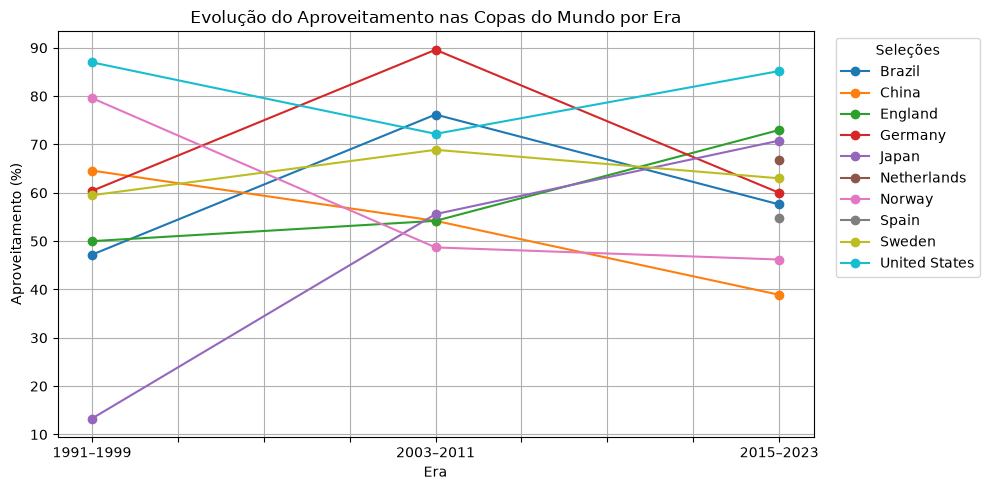

In [57]:
# CONSOLIDAÇÃO DA TABELA RESUMO
# Títulos, vices e participações vêm do `historico` (1.1); aqui só se calcula o que é novo na Q3
resumo_geral = (
    stats_edicao.groupby('team')
    .agg(
        total_jogos=('jogos', 'sum'), vitorias_totais=('vitorias', 'sum'),
        gols_pro_totais=('gols_pro', 'sum'), saldo_total=('saldo_gols', 'sum'),
    ).reset_index()
)

base_hist = (
    historico.rename(columns={'Seleção': 'team', 'Participações': 'edicoes_jogadas',
                              'Títulos': 'titulos', 'Vices': 'vices'})
    [['team', 'edicoes_jogadas', 'titulos', 'vices']]
)

# Total de pódios (top 3)
podios_3 = (
    pd.concat([df_podios_ano['campea'], df_podios_ano['vice'], df_podios_ano['terceiro']])
    .value_counts().rename_axis('team').rename('podios').reset_index()
)

# Nível máximo de profundidade atingido, em texto
niveis_inverso = {v: k for k, v in niveis.items()}
max_nivel_df = (stats_edicao.groupby('team')['nivel'].max().map(niveis_inverso)
                .rename('max_nivel').reset_index())

tendencias_df = piv_aprov[['variacao_pp', 'variacao_moderna', 'tendencia']].reset_index()

tabela_resumo = (
    resumo_geral.merge(base_hist, on='team', how='left')
    .merge(podios_3, on='team', how='left')
    .merge(max_nivel_df, on='team', how='left')
    .merge(tendencias_df, on='team', how='left')
)
tabela_resumo['podios'] = tabela_resumo['podios'].fillna(0).astype(int)
tabela_resumo = (
    tabela_resumo[['team', 'edicoes_jogadas', 'titulos', 'vices', 'podios', 'max_nivel',
                   'total_jogos', 'vitorias_totais', 'gols_pro_totais', 'saldo_total',
                   'variacao_pp', 'variacao_moderna', 'tendencia']]
    .sort_values(['titulos', 'podios'], ascending=False)
    .reset_index(drop=True)
)

print('=== TABELA RESUMO CONSOLIDADA DAS SELEÇÕES ===')
display(tabela_resumo)

# Gráfico de Linha: Evolução por Era
ax = piv_aprov[LABELS].T.plot(marker='o', figsize=(10, 5), grid=True)
ax.set_title('Evolução do Aproveitamento nas Copas do Mundo por Era')
ax.set_ylabel('Aproveitamento (%)')
ax.set_xlabel('Era')
ax.legend(title='Seleções', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Conclusões**

**Medida usada:** todas as variações em p.p. abaixo se referem ao aproveitamento **só em jogos de Copa do Mundo**, por era. "Geral" compara 2015–2023 com 1991–1999 e "era moderna" compara 2015–2023 com 2003–2011. Não são comparáveis com a ascensão competitiva 2010s → 2020s* da 1.3, 1.5 e Q2 (ver Premissas).
- **EUA:** 4 títulos e 8 pódios em 9 edições, com 41 vitórias em 54 jogos. Mantém-se estável tanto na variação geral (-1,8 pp) quanto na era moderna (+13,0 pp).
- **Alemanha:** 2 títulos, mas apresenta uma queda expressiva na era moderna (-29,6 pp), embora mantenha estabilidade no comparativo histórico amplo (-0,4 pp).
- **Japão é a maior ascensão:** Grande ascensão histórica (+57,5 pp entre 1991–1999 e 2015–2023), de coadjuvante a campeão em 2011, consolidando também um crescimento positivo na era moderna (+15,2 pp).
- **Inglaterra:** Crescimento sólido e contínuo, com +23,0 pp no geral e +18,8 pp na era moderna, coroado com o vice-campeonato em 2023.
- **Suécia:** Estável no comparativo histórico (+3,5 pp), mas com leve recuo na era moderna (-5,9 pp); destaca-se pelos 5 pódios (segundo maior número atrás apenas dos EUA).
-  **Brasil:** Apresenta alta histórica (+10,4 pp) com um vice em 2007, mas sofre uma retração na era moderna (-18,6 pp).
- **Noruega e China decaíram:** A Noruega caiu -33,4 pp no geral (e levemente -2,5 pp na era moderna), enquanto a China despencou -25,7 pp no geral e -15,3 pp na era moderna.
- **Espanha e Holanda** só aparecem na era moderna, com 3 edições cada, então não há comparação de eras: a Espanha foi campeã em 2023 e a Holanda vice em 2019.
- **Leitura:** o topo é estável (EUA e Alemanha), mas o meio muda. Japão e Inglaterra subiram de forma contínua; Brasil, Alemanha e Suécia tiveram o pico em 2003–2011 e recuaram depois; os EUA caíram nessa era e se recuperaram; Noruega e China decaíram, o que indica renovação, e não só consolidação das tradicionais.

**Limitações:** cada seleção tem poucos jogos por era (4 a 6 por edição); o aproveitamento não considera a fase; a fase é inferida pelo número de jogos; as seleções são as 10 finalistas de Copa, ou seja, a elite histórica da 1.5 mais Holanda e Espanha; e o limiar de ±5 pp (`LIMIAR_PP`, o mesmo da 1.5) é pequeno diante de tão poucos jogos, mas com 10 pp os rótulos seriam os mesmos. As demais ressalvas estão nas Premissas.

#### Resposta (Q3)

Nas Copas, o topo é estável (EUA e Alemanha) e o meio muda: Japão e Inglaterra subiram, Noruega e China caíram, e Brasil, Alemanha e Suécia tiveram o pico em 2003–2011 e recuaram depois; são variações só de jogos de Copa.

### 4. Como o número de jogos e seleções participantes evoluiu ao longo do tempo?

Evolução anual de partidas (competitivas e não competitivas) e de seleções ativas; depois, as seleções ativas por década e confederação, as edições da Copa do Mundo e um resumo por década.

- **Recorte:** até 2025, para excluir 2026 (ano parcial)
- **Confederação é um proxy:** cada seleção recebe a confederação dos torneios que mais disputou, e as que não aparecem nos torneios mapeados ficam em "Sem confederação identificada"

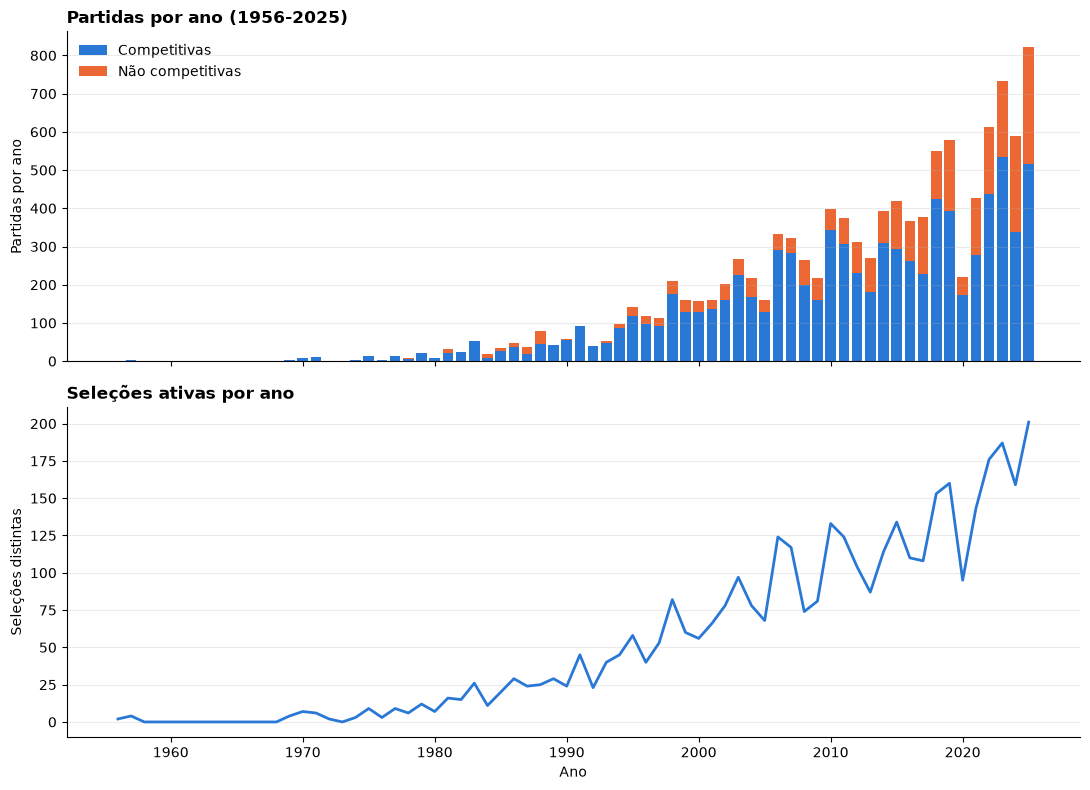

In [58]:
ANO_MAX = 2025

COR_COMP = '#2a78d6'     # competitivas
COR_NAO_COMP = '#eb6834' # não competitivas
COR_TOTAL = '#2a78d6'

anual = resultados[resultados['year'] <= ANO_MAX]
long_annual = matches_long[matches_long['year'] <= ANO_MAX]

# Partidas por ano
partidas_ano = (
    anual.groupby(['year', 'is_competitive']).size()
    .unstack(fill_value=0)
    .rename(columns={True: 'competitivas', False: 'nao_competitivas'})
    .reindex(columns=['competitivas', 'nao_competitivas'], fill_value=0)
    .reindex(range(anual['year'].min(), ANO_MAX + 1), fill_value=0)
)

# Seleções distintas por ano
selecoes_ano = (long_annual.groupby('year')['team'].nunique()
                .reindex(partidas_ano.index, fill_value=0).rename('total').to_frame())

# Gráfico com 2 painéis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

# Painel 1: Partidas por ano (barras empilhadas)
ax1.bar(partidas_ano.index, partidas_ano['competitivas'], color=COR_COMP, label='Competitivas')
ax1.bar(partidas_ano.index, partidas_ano['nao_competitivas'], bottom=partidas_ano['competitivas'], color=COR_NAO_COMP, label='Não competitivas')
ax1.set_ylabel('Partidas por ano')
ax1.set_title(f'Partidas por ano ({partidas_ano.index.min()}-{ANO_MAX})', loc='left', fontweight='bold')
ax1.legend(frameon=False, loc='upper left')

# Painel 2: Seleções distintas por ano (linhas)
ax2.plot(selecoes_ano.index, selecoes_ano['total'], color=COR_TOTAL, linewidth=2, label='Seleções ativas')
ax2.set_ylabel('Seleções distintas')
ax2.set_xlabel('Ano')
ax2.set_title('Seleções ativas por ano', loc='left', fontweight='bold')

# Estilização comum
for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

In [59]:
SEM_CONF = 'Sem confederação identificada'
# O dicionário de torneios por confederação (proxy), TORNEIOS_CONFEDERACAO, vem de config.py

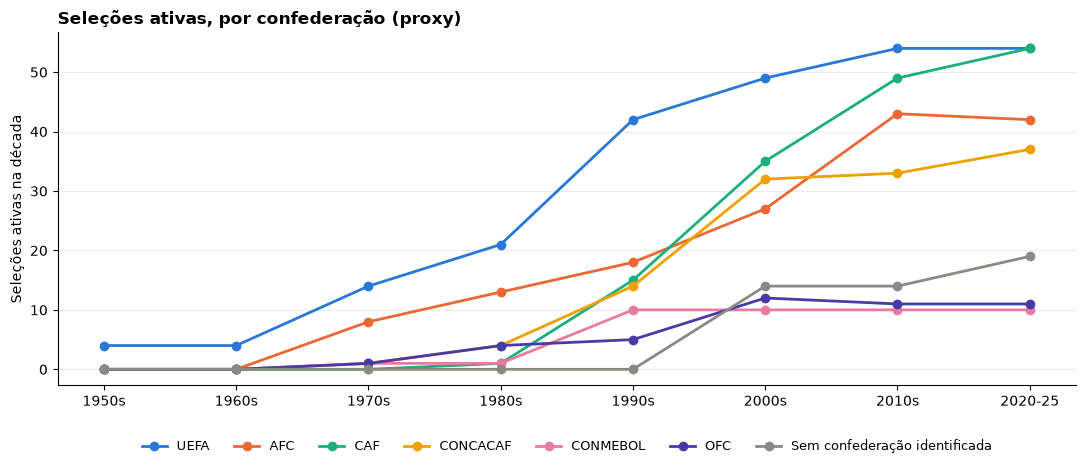

In [60]:
# Proxy de confederação por seleção
torneio_para_conf = {t: conf for conf, ts in TORNEIOS_CONFEDERACAO.items() for t in ts}

jogos_conf = matches_long.assign(conf_torneio=matches_long['tournament'].map(torneio_para_conf)).dropna(subset=['conf_torneio'])
contagem_conf = jogos_conf.groupby(['team', 'conf_torneio']).size().unstack(fill_value=0)

todas_selecoes = matches_long['team'].unique()
conf_selecoes = contagem_conf.idxmax(axis=1).reindex(todas_selecoes).fillna(SEM_CONF)

ordem_conf = ['UEFA', 'AFC', 'CAF', 'CONCACAF', 'CONMEBOL', 'OFC', SEM_CONF]

# Contagem de seleções ativas por década
ativas_conf = (
    matches_long[matches_long['year'] <= ANO_MAX]
    .assign(confederacao=lambda d: d['team'].map(conf_selecoes))
    .groupby(['decade', 'confederacao'])['team'].nunique()
    .unstack(fill_value=0)
    .reindex(columns=ordem_conf, fill_value=0)
)

# Rótulos e Cores
CORES_CONF = {
    'UEFA': '#2a78d6', 'AFC': '#eb6834', 'CAF': '#1baf7a',
    'CONCACAF': '#eda100', 'CONMEBOL': '#e87ba4', 'OFC': '#4a3aa7',
    SEM_CONF: '#8a8984'
}
rotulos_decada = [f"{d}s" if d < 2020 else '2020-25' for d in ativas_conf.index]

# Gráfico de Seleções Ativas
fig, ax = plt.subplots(figsize=(11, 4.8))

for conf in ordem_conf:
    ax.plot(rotulos_decada, ativas_conf[conf], marker='o', linewidth=2, color=CORES_CONF[conf], label=conf)

ax.set_ylabel('Seleções ativas na década')
ax.set_title('Seleções ativas, por confederação (proxy)', loc='left', fontweight='bold')
ax.legend(frameon=False, ncol=7, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=9)

ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

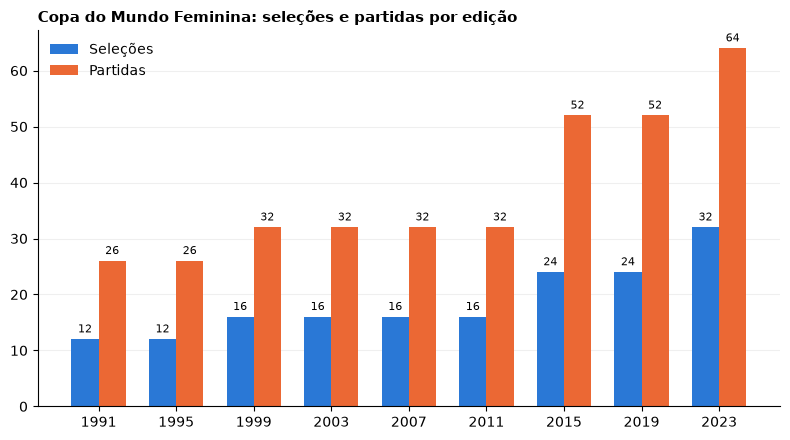

In [61]:
# Edições da Copa do Mundo: seleções e partidas por edição
d = resultados[resultados['tournament'] == 'FIFA World Cup']
times = pd.concat([d[['year', 'home_team']].rename(columns={'home_team': 'team'}),
                   d[['year', 'away_team']].rename(columns={'away_team': 'team'})])
ed_copa = pd.DataFrame({'selecoes': times.groupby('year')['team'].nunique(),
                        'partidas': d.groupby('year').size()})

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(ed_copa))
largura = 0.35
b1 = ax.bar(x - largura/2, ed_copa['selecoes'], largura, color='#2a78d6', label='Seleções')
b2 = ax.bar(x + largura/2, ed_copa['partidas'], largura, color='#eb6834', label='Partidas')
ax.bar_label(b1, fontsize=8, padding=3)
ax.bar_label(b2, fontsize=8, padding=3)
ax.set_xticks(x)
ax.set_xticklabels(ed_copa.index)
ax.set_title('Copa do Mundo Feminina: seleções e partidas por edição', loc='left', fontweight='bold', fontsize=11)
ax.legend(frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [62]:
# Resumo por década (níveis médios; 2020-25 é parcial)
PRIMEIRO_ANO = int(resultados['year'].min())
decadas = sorted(anual['decade'].unique())
anos_na_decada = pd.Series({d: len(range(max(d, PRIMEIRO_ANO), min(d + 9, ANO_MAX) + 1)) for d in decadas})

primeira_partida = matches_long.groupby('team')['date'].min().dt.year
primeira_partida = primeira_partida[primeira_partida <= ANO_MAX]

resumo_decada = pd.DataFrame({
    'Partidas por ano': anual.groupby('decade').size().div(anos_na_decada),
    'Competitivas por ano': anual[anual['is_competitive']].groupby('decade').size().div(anos_na_decada),
    '% amistosos': anual.groupby('decade')['tournament'].apply(lambda t: 100 * (t == 'Friendly').mean()),
    'Seleções ativas (média anual)': selecoes_ano['total'].groupby((selecoes_ano.index // 10) * 10).mean(),
    'Estreias de seleções': (primeira_partida // 10 * 10).value_counts(),
}).loc[1980:]
resumo_decada.index = [f'{d}s' if d < 2020 else '2020-25' for d in resumo_decada.index]
display(resumo_decada.round(1))

,Partidas por ano,Competitivas por ano,% amistosos,Seleções ativas (média anual),Estreias de seleções
1980s,37.8,28.9,0.0,20.2,22
1990s,108.1,93.3,1.2,47.0,59
2000s,229.7,188.3,2.4,83.9,80
2010s,404.0,297.1,7.1,122.7,42
2020-25,567.2,379.2,24.8,160.2,16


**Conclusões**

- **Crescimento a cada década, em parte por cobertura:** de cerca de 38 partidas por ano e 20 seleções ativas nos anos 1980 para cerca de 570 e 160 em 2020–25, e a Copa passou de 12 para 32 seleções. Mas o dataset é colaborativo e documenta pior as décadas antigas, e os amistosos vão de 0% das partidas nos anos 1980 para 25% em 2020–25. Só com as competitivas, o crescimento é de cerca de 29 para 379 partidas por ano (13 vezes, contra 15 no total), o que ainda aponta crescimento real, mas de tamanho incerto.
- **Menos seleções novas:** as estreias chegaram ao máximo nos anos 2000 (80) e caíram para 16 em 2020–25, enquanto as seleções ativas seguem subindo, o que sugere que seleções que já existiam passaram a jogar com mais regularidade.
- **Quem puxou:** CAF e CONCACAF cresceram muito desde os anos 80 (a CAF alcança a UEFA em 2020–25); a AFC estabilizou desde 2010; CONMEBOL e OFC ficam em ~10 seleções.

> Nota: dados por confederação são aproximados (proxy por torneios); 2026 foi excluído por ser ano parcial; o dataset inclui 9 jogos de entidades CONIFA em 11.650, de impacto desprezível.

#### Resposta (Q4)
O número de partidas por ano e de seleções ativas cresceu a cada década (em parte por melhor cobertura do dataset, sobretudo de amistosos). Porém, entrada de seleções novas perde ritmo desde os anos 2000, o que sugere que o crescimento recente do número de partidas vem de seleções já existentes jogando mais. E a Copa passou de 12 para 32 seleções.

### 5. O nível de jogo (aferido por gols e goleadas) mudou ao longo das edições da Copa do Mundo? As edições mais recentes são mais disputadas ou mais desiguais?


Cada jogo da Copa FIFA (1991–2023) é classificado por fase (grupos ou mata-mata) e por presença de estreante (seleção na sua primeira Copa). O indicador de nível é a **média de gols por jogo** e a **% de goleadas** (diferença ≥ 4 gols). Compara-se o conjunto das edições, a fase de cada goleada e jogos com e sem estreantes.

**Limitações:** a Copa passa de 12 para 32 seleções, então as edições não são diretamente comparáveis; há poucos jogos por edição; e gols são um indicador aproximado de equilíbrio, não de qualidade técnica.

In [63]:
# Intenção: gols por jogo, goleadas e fase das goleadas por edição da Copa do Mundo FIFA
LIMITE_GOLEADA = 4

copa_wide = resultados[resultados['tournament'] == 'FIFA World Cup'].copy()
copa_wide['is_goleada'] = copa_wide['goal_difference'].abs() >= LIMITE_GOLEADA

# Fase do jogo: os primeiros 1,5 × nº de seleções jogos da edição (por data) são da fase de grupos
# (grupos de 4 seleções = 6 jogos por grupo); os demais são mata-mata
copa_wide = copa_wide.sort_values(['year', 'date', 'match_id']).reset_index(drop=True)
selecoes_por_ano = (pd.concat([copa_wide[['year', 'home_team']].rename(columns={'home_team': 'team'}),
                               copa_wide[['year', 'away_team']].rename(columns={'away_team': 'team'})])
                    .groupby('year')['team'].nunique())
jogos_de_grupo = (selecoes_por_ano * 1.5).astype(int)
copa_wide['fase'] = np.where(copa_wide.groupby('year').cumcount() < copa_wide['year'].map(jogos_de_grupo),
                           'Grupos', 'Mata-mata')

# Validação: mata-mata esperado = 8 jogos até 2011 e 16 a partir de 2015
mata_por_ano = copa_wide[copa_wide['fase'] == 'Mata-mata'].groupby('year').size()
assert (mata_por_ano == [8 if y <= 2011 else 16 for y in mata_por_ano.index]).all(), 'Fase inferida inconsistente'

qualidade = (
    copa_wide.groupby('year')
        .agg(jogos=('match_id', 'count'),
             gols=('total_goals', 'sum'),
             media_gols=('total_goals', 'mean'),
             goleadas=('is_goleada', 'sum'))
        .assign(pct_goleadas=lambda d: (d['goleadas'] / d['jogos'] * 100).round(1),
                media_gols=lambda d: d['media_gols'].round(2))
)

# Goleadas por fase, na própria tabela
gol_fase = (copa_wide[copa_wide['is_goleada']].groupby(['year', 'fase']).size()
            .unstack(fill_value=0)
            .reindex(columns=['Grupos', 'Mata-mata'], fill_value=0)
            .reindex(qualidade.index, fill_value=0))
qualidade['goleadas_grupos'] = gol_fase['Grupos']
qualidade['goleadas_mata_mata'] = gol_fase['Mata-mata']
qualidade['fase_com_mais_goleadas'] = np.select(
    [gol_fase['Grupos'] > gol_fase['Mata-mata'], gol_fase['Grupos'] < gol_fase['Mata-mata']],
    ['Grupos', 'Mata-mata'], default='Empate')

qualidade

,jogos,gols,media_gols,goleadas,pct_goleadas,goleadas_grupos,goleadas_mata_mata,fase_com_mais_goleadas
year,,,,,,,,
1991,26,99,3.81,8,30.8,6,2,Grupos
1995,26,99,3.81,5,19.2,4,1,Grupos
1999,32,123,3.84,8,25.0,7,1,Grupos
2003,32,107,3.34,5,15.6,4,1,Grupos
2007,32,111,3.47,7,21.9,6,1,Grupos
2011,32,86,2.69,2,6.2,2,0,Grupos
2015,52,146,2.81,6,11.5,6,0,Grupos
2019,52,146,2.81,5,9.6,5,0,Grupos
2023,64,164,2.56,12,18.8,10,2,Grupos


In [64]:
# Primeira edição de cada seleção na Copa FIFA
primeira = pd.concat([copa_wide[['year', 'home_team']].rename(columns={'home_team': 'team'}),
                      copa_wide[['year', 'away_team']].rename(columns={'away_team': 'team'})]
                    ).groupby('team')['year'].min()

copa_wide['mand_estreante'] = copa_wide['home_team'].map(primeira) == copa_wide['year']
copa_wide['vis_estreante'] = copa_wide['away_team'].map(primeira) == copa_wide['year']
copa_wide['jogo_com_estreante'] = copa_wide['mand_estreante'] | copa_wide['vis_estreante']

# Perdedor (empates ficam nulos; goleadas nunca são empate)
copa_wide['perdedor'] = np.where(copa_wide['home_score'] < copa_wide['away_score'], copa_wide['home_team'],
                      np.where(copa_wide['home_score'] > copa_wide['away_score'], copa_wide['away_team'], None))
copa_wide['perdedor_estreante'] = copa_wide['perdedor'].map(primeira) == copa_wide['year']

def resumo_edicao(d):
    com = d['jogo_com_estreante']
    # Calcula o total de seleções únicas na edição atual (d)
    total_selecoes = pd.concat([d['home_team'], d['away_team']]).nunique()
    
    return pd.Series({
        'total_selecoes': int(total_selecoes),
        'estreantes': int((primeira == d.name).sum()),
        'jogos': len(d),
        'jogos_c_estreante': int(com.sum()),
        'goleadas': int(d['is_goleada'].sum()),
        'goleadas_sofridas_estreante': int((d['is_goleada'] & d['perdedor_estreante']).sum()),
        '%_goleadas_c_estreante': round(d.loc[com, 'is_goleada'].mean() * 100, 1),
        '%_goleadas_s_estreante': round(d.loc[~com, 'is_goleada'].mean() * 100, 1),
    })

estreantes_edicao = (
    copa_wide[copa_wide['year'] > 1991]
        .groupby('year')
        .apply(resumo_edicao)
        .convert_dtypes()
)
estreantes_edicao

,total_selecoes,estreantes,jogos,jogos_c_estreante,goleadas,goleadas_sofridas_estreante,%_goleadas_c_estreante,%_goleadas_s_estreante
year,,,,,,,,
1995,12,3,26,9,5,2,22.2,17.6
1999,16,4,32,13,8,3,30.8,21.1
2003,16,3,32,8,5,3,37.5,8.3
2007,16,0,32,0,7,0,<NA>,21.9
2011,16,2,32,6,2,0,0.0,7.7
2015,24,8,52,22,6,5,22.7,3.3
2019,24,4,52,12,5,2,16.7,7.5
2023,32,8,64,24,12,7,29.2,12.5


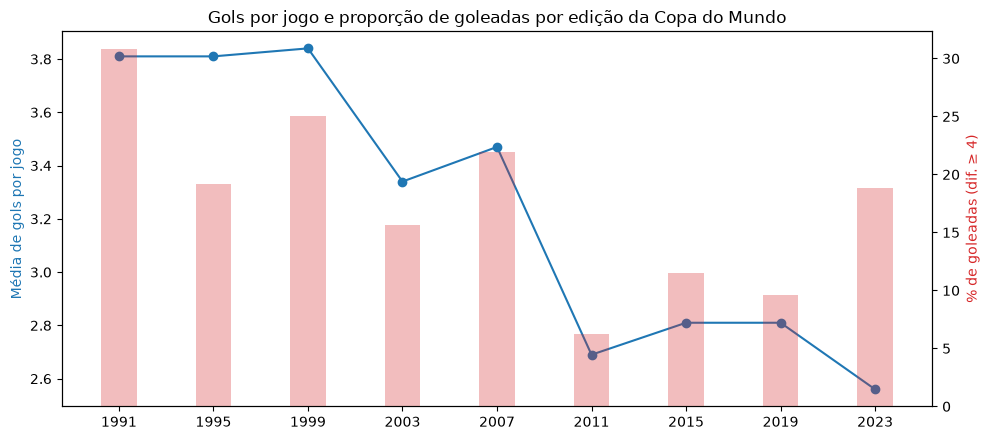

In [65]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))

ax1.plot(qualidade.index, qualidade['media_gols'], marker='o', color='tab:blue')
ax1.set_ylabel('Média de gols por jogo', color='tab:blue')
ax1.set_xticks(qualidade.index)

ax2 = ax1.twinx()
ax2.bar(qualidade.index, qualidade['pct_goleadas'], alpha=0.3, color='tab:red', width=1.5)
ax2.set_ylabel(f'% de goleadas (dif. ≥ {LIMITE_GOLEADA})', color='tab:red')

ax1.set_title('Gols por jogo e proporção de goleadas por edição da Copa do Mundo')
plt.tight_layout()
plt.show()

**Conclusões**

- **Menos gols:** a média caiu de cerca de 3,6 por jogo (1991–2007) para cerca de 2,7 (2011–2023), e 2023 tem a menor da série (2,56).
- **Goleadas:** representavam cerca de 22% dos jogos em 1991–2007, caem para cerca de 10% em 2011–2019 e sobem para 18,8% em 2023 (12 jogos, o maior número da série).
- **A expansão pesa:** a Copa passou de 12 para 32 seleções, e 2015 e 2023 tiveram 8 estreantes cada. Em 2015, 5 das 6 goleadas foram sofridas por estreantes; em 2023, 7 das 12. Jogos com estreantes terminam mais em goleada (29,2% contra 12,5% em 2023).
- **Estreantes não explicam tudo:** mesmo sem estreantes, 2023 teve mais goleadas (12,5%) do que 2015 (3,3%) e 2019 (7,5%).
- **Fase:** 10 das 12 goleadas de 2023 foram na fase de grupos. Na série toda, 50 das 58 goleadas (86%) ocorreram nos grupos, onde 19,8% dos jogos terminam em goleada, contra 8,3% no mata-mata (que não teve nenhuma em 2015 e 2019). Isso é compatível com adversários mais desiguais antes dos cruzamentos.

**Limitações:** menos gols não significa menor nível técnico (pode refletir defesas mais organizadas); o limiar de 4 gols não foi testado com outros valores; há poucos jogos por edição (26 a 64); e as edições têm tamanhos diferentes.

#### Resposta (Q5)
As Copas do Mundo tornaram-se mais disputadas até 2019 (com menos gols por jogo e menos goleadas), contudo a edição de 2023 reverteu parte desse equilíbrio, com a taxa de goleadas subindo para 18,8%, num torneio ampliado para 32 seleções em que 7 das 12 goleadas foram sofridas por estreantes. A expansão é um fator plausível, mas não o único.

### 6. Jogar em casa é uma vantagem real no futebol feminino?

   Duas análises complementares:

   1. **Geral:** cada seleção é comparada com ela mesma, em casa e fora, nos jogos com mando definido (`neutral == False`). O dataset marca como neutros os jogos disputados fora do país de ambos os times, o que deixa de fora 300 dos 348 jogos de Copa do Mundo. Ficam os 48 jogos da seleção-sede, que o dataset marca como não neutros (conferido na célula seguinte).
   2. **Seleção-sede em Copas:** compara a seleção-sede jogando em casa com as mesmas seleções em Copas em que não foram sede, sem enfrentar a sede. As sedes de cada edição vêm de uma lista manual.

   **Limitações:** a análise geral controla a força de cada time, mas não a do adversário nem o tipo de jogo; a da seleção-sede não controla a força dos times; cada seleção-sede tem só 4 a 7 jogos por edição; e os 48 jogos da sede em Copas aparecem nas duas análises.

todos os jogos com mando: 88 seleções | casa − fora = +17.0 p.p. (erro-padrão 1.4) | 82 de 88 rendem mais em casa
só competitivos: 69 seleções | casa − fora = +11.5 p.p. (erro-padrão 1.2) | 62 de 69 rendem mais em casa


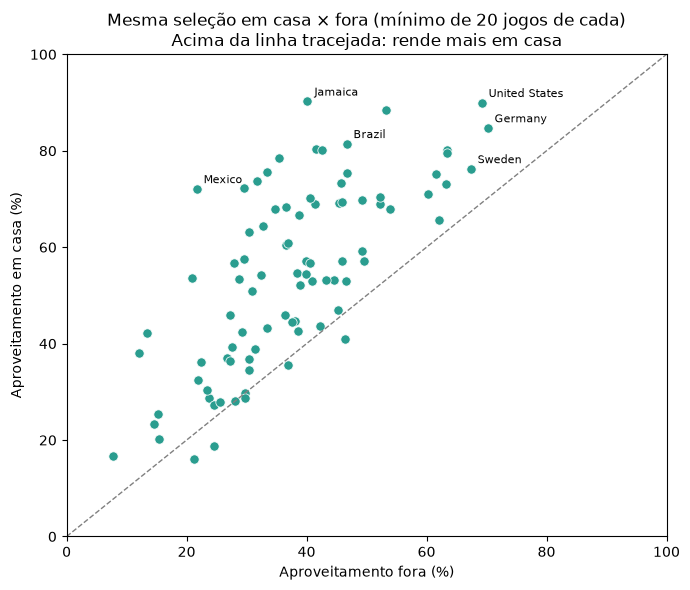

In [66]:
home_games = resultados[resultados['neutral'] == False]   # usado na checagem de incerteza mais abaixo

# Mesma seleção em casa × fora (jogos com mando definido): compara cada seleção com ela mesma, o que controla a força do time
MIN_JOGOS_MANDO = 20
jogos_mando = matches_long[~matches_long['neutral']]

def mando_por_selecao(df, min_jogos=MIN_JOGOS_MANDO):
    t = (df.groupby(['team', 'venue'])
           .agg(jogos=('points', 'size'), aproveit=('points', lambda p: 100 * p.mean() / 3))
           .unstack('venue'))
    t = t[(t[('jogos', 'home')] >= min_jogos) & (t[('jogos', 'away')] >= min_jogos)]
    return pd.DataFrame({'casa': t[('aproveit', 'home')], 'fora': t[('aproveit', 'away')]})

for rotulo, df in {'todos os jogos com mando': jogos_mando,
                   'só competitivos': jogos_mando[jogos_mando['is_competitive']]}.items():
    m = mando_por_selecao(df)
    dif = m['casa'] - m['fora']
    ep = dif.std() / np.sqrt(len(dif))
    print(f'{rotulo}: {len(m)} seleções | casa − fora = {dif.mean():+.1f} p.p. (erro-padrão {ep:.1f}) | {int((dif > 0).sum())} de {len(m)} rendem mais em casa')

# Gráfico: uma bolinha por seleção; acima da diagonal = rende mais em casa
m_todos = mando_por_selecao(jogos_mando)
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=m_todos, x='fora', y='casa', ax=ax, color='#2A9D8F', s=45)
ax.plot([0, 100], [0, 100], color='gray', ls='--', lw=1)
for t in ['United States', 'Germany', 'Brazil', 'Sweden', 'Mexico', 'Jamaica']:
    if t in m_todos.index:
        ax.annotate(t, (m_todos.loc[t, 'fora'], m_todos.loc[t, 'casa']), textcoords='offset points', xytext=(5, 4), fontsize=8)
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel='Aproveitamento fora (%)', ylabel='Aproveitamento em casa (%)',
       title='Mesma seleção em casa × fora (mínimo de 20 jogos de cada)\nAcima da linha tracejada: rende mais em casa')
plt.tight_layout()
plt.show()

In [67]:
# Checagem: os jogos da seleção-sede em Copas do Mundo estão marcados como não neutros
resultados[(resultados['tournament'] == 'FIFA World Cup')
           & (resultados['home_team'] == resultados['country'])]['neutral'].value_counts()

neutral
False    48
Name: count, dtype: int64

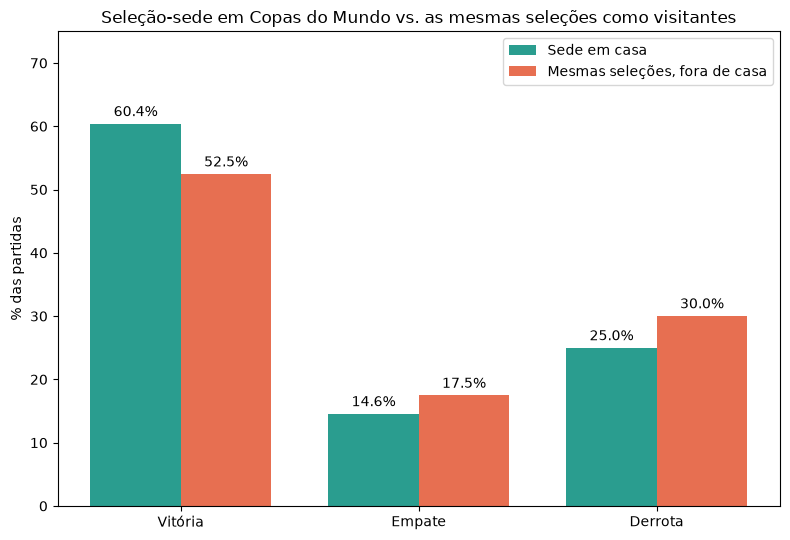

,Ano,Seleção-Sede,Total de Edições Participadas,Aproveitamento como Sede (%),Aproveitamento Médio (Outras Edições) (%)
0,1991,China,8,58.3,57.3
1,1995,Sweden,9,58.3,64.2
2,1999,United States,9,88.9,79.7
3,2003,United States,9,83.3,79.7
4,2007,China,8,50.0,57.3
5,2011,Germany,9,75.0,72.5
6,2015,Canada,8,53.3,37.9
7,2019,France,5,80.0,60.8
8,2023,Australia,8,47.6,34.6
9,2023,New Zealand,6,44.4,5.6


In [68]:
# Sedes por edição (2027 fica de fora: ainda não há jogos)
sedes_copa = {
    1991: ['China'],
    1995: ['Sweden'],
    1999: ['United States'],
    2003: ['United States'],
    2007: ['China'],
    2011: ['Germany'],
    2015: ['Canada'],
    2019: ['France'],
    2023: ['Australia', 'New Zealand'],
}

copa_long = matches_long[matches_long['tournament'] == 'FIFA World Cup'].copy()
copa_long['is_host']     = [t in sedes_copa.get(y, []) for t, y in zip(copa_long['team'], copa_long['year'])]
copa_long['opp_is_host'] = [o in sedes_copa.get(y, []) for o, y in zip(copa_long['opponent'], copa_long['year'])]

# sede jogando em casa (exclui sede x sede)
jogos_sede = copa_long[copa_long['is_host'] & ~copa_long['opp_is_host']]
# mesmas seleções em Copas em que NÃO eram sede (e sem enfrentar a sede)
selecoes_sede = set(jogos_sede['team'])
baseline = copa_long[copa_long['team'].isin(selecoes_sede) & ~copa_long['is_host'] & ~copa_long['opp_is_host']]

# Gráfico de comparativo geral
ordem = ['win', 'draw', 'loss']
dist = pd.DataFrame({
    'Sede em casa': jogos_sede['outcome'].value_counts(normalize=True).reindex(ordem) * 100,
    'Mesmas seleções, fora de casa': baseline['outcome'].value_counts(normalize=True).reindex(ordem) * 100,
}).fillna(0)

fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(3); w = 0.38
b1 = ax.bar(x - w/2, dist['Sede em casa'], w, label='Sede em casa', color='#2A9D8F')
b2 = ax.bar(x + w/2, dist['Mesmas seleções, fora de casa'], w, label='Mesmas seleções, fora de casa', color='#E76F51')
ax.bar_label(b1, fmt='%.1f%%', padding=3); ax.bar_label(b2, fmt='%.1f%%', padding=3)
ax.set_xticks(x, ['Vitória', 'Empate', 'Derrota'])
ax.set_ylabel('% das partidas'); ax.set_ylim(0, 75); ax.legend()
ax.set_title('Seleção-sede em Copas do Mundo vs. as mesmas seleções como visitantes')
plt.tight_layout()
plt.show()

# Calcula o aproveitamento da sede em cada edição específica
aproveitamento_sede_edicao = (
    jogos_sede.groupby(['year', 'team'])
    .agg(aproveit_sede=('points', lambda p: 100 * p.mean() / 3))
    .reset_index()
)

# Calcula o aproveitamento médio da mesma seleção nas OUTRAS edições (fora de casa)
aproveitamentos_outras = []
for _, row in aproveitamento_sede_edicao.iterrows():
    ano = row['year']
    selecao = row['team']
    
    # Filtra jogos da seleção em outras Copas (excluindo o ano sede)
    jogos_outras = baseline[baseline['team'] == selecao]
    aproveit_outras = 100 * jogos_outras['points'].mean() / 3 if len(jogos_outras) > 0 else 0
    
    # Conta quantas edições (anos distintos) essa seleção participou no total em Copas
    total_edicoes = copa_long[copa_long['team'] == selecao]['year'].nunique()
    
    aproveitamentos_outras.append({
        'Ano': ano,
        'Seleção-Sede': selecao,
        'Total de Edições Participadas': total_edicoes,
        'Aproveitamento como Sede (%)': round(row['aproveit_sede'], 1),
        'Aproveitamento Médio (Outras Edições) (%)': round(aproveit_outras, 1)
    })

tabela_final = pd.DataFrame(aproveitamentos_outras)
display(tabela_final)

In [69]:
# Incerteza dos comparativos: erro-padrão da diferença de proporções e teste do sinal por edição
from math import comb

# 1) Seleção-sede em casa x as mesmas seleções fora de casa (% de vitórias)
p_s, n_s = (jogos_sede['outcome'] == 'win').mean(), len(jogos_sede)
p_b, n_b = (baseline['outcome'] == 'win').mean(), len(baseline)
dif = p_s - p_b
ep = np.sqrt(p_s * (1 - p_s) / n_s + p_b * (1 - p_b) / n_b)
print(f'Sede: {p_s:.1%} ({n_s} jogos) | Baseline: {p_b:.1%} ({n_b} jogos)')
print(f'Diferença: {dif*100:+.1f} p.p. | erro-padrão: {ep*100:.1f} p.p. | IC 95%: [{(dif - 1.96*ep)*100:+.1f}, {(dif + 1.96*ep)*100:+.1f}] p.p.')

# 2) Sede acima do baseline em quantas edições (teste do sinal bilateral, H0: 50%)
n_ed = len(tabela_final)
melhor = int((tabela_final['Aproveitamento como Sede (%)'] > tabela_final['Aproveitamento Médio (Outras Edições) (%)']).sum())
p_sinal = min(1, 2 * sum(comb(n_ed, k) for k in range(max(melhor, n_ed - melhor), n_ed + 1)) / 2**n_ed)
print(f'Sede acima do baseline em {melhor} de {n_ed} edições | teste do sinal bilateral: p = {p_sinal:.2f}')

# 3) Agregado (neutral == False): mandante x visitante
n_h = len(home_games)
p_m = (home_games['match_outcome'] == 'home_win').mean()
p_v = (home_games['match_outcome'] == 'away_win').mean()
ep_h = np.sqrt((p_m + p_v - (p_m - p_v) ** 2) / n_h)
print(f'Agregado: {n_h} jogos | mandante {p_m:.1%} − visitante {p_v:.1%} = {(p_m - p_v)*100:+.1f} p.p. | erro-padrão: {ep_h*100:.1f} p.p.')

Sede: 60.4% (48 jogos) | Baseline: 52.5% (223 jogos)
Diferença: +8.0 p.p. | erro-padrão: 7.8 p.p. | IC 95%: [-7.4, +23.3] p.p.
Sede acima do baseline em 8 de 10 edições | teste do sinal bilateral: p = 0.11
Agregado: 6930 jogos | mandante 52.0% − visitante 33.8% = +18.2 p.p. | erro-padrão: 1.1 p.p.


**Conclusões**

- **Mesma seleção, em casa × fora:** nas 88 seleções com pelo menos 20 jogos com mando definido de cada tipo, o aproveitamento é em média 17,0 p.p. maior em casa (erro-padrão 1,4), e 82 delas rendem mais em casa; só com jogos competitivos são 69 seleções, +11,5 p.p. (62 rendem mais em casa). Comparar cada seleção com ela mesma controla a força do time (o agregado simples, 52,0% de vitórias do mandante contra 33,8% do visitante, mistura times fortes e fracos), mas não a do adversário nem o tipo de jogo.
- **Seleção-sede em Copas:** comparando as mesmas seleções (48 jogos como sede contra 223 como não sede), as vitórias subiram de 52,5% para 60,4% (+8,0 p.p.) e as derrotas caíram de 30,0% para 25,0% (−5,0 p.p.). O erro-padrão da diferença de vitórias é de cerca de 7,8 p.p. (IC 95%: −7,4 a +23,3 p.p.), então a diferença não se distingue do acaso.
- **Por edição:** o aproveitamento (pontos conquistados ÷ pontos possíveis) da sede foi maior que o das outras edições em 8 dos 10 casos (teste do sinal bilateral, p ≈ 0,11). É um indício consistente na direção esperada, mas sem significância. As exceções são Suécia (1995) e China (2007), com diferenças de −5,9 e −7,3 p.p.

**E o Brasil em 2027:** como sede, o Brasil tem a vantagem geral de jogar em casa, mas o tamanho do ganho em uma Copa não é conhecido.

**Limitações**

- Cada seleção-sede tem de 4 a 7 jogos por edição, então as diferenças individuais são sensíveis a poucos resultados.
- O baseline mistura edições de épocas diferentes: a seleção pode ter melhorado ou piorado entre a Copa em que foi sede e as demais. O caso mais extremo é a Nova Zelândia (44,4% contra 5,6%), cujo baseline vem de uma seleção que pontuou muito pouco antes de 2023.
- A concentração dos maiores ganhos em 2015–2023 pode também refletir o formato com mais seleções, em que a sede enfrenta adversários mais fracos na fase de grupos; isso não foi separado.
- Os 48 jogos da seleção-sede em Copas entram nas duas análises, então elas não são totalmente independentes.
- Os intervalos e testes acima são aproximados: tratam as amostras como independentes, ignorando que as mesmas seleções aparecem nos dois grupos e que algumas edições repetem a sede (EUA e China).
- O comparativo casa × fora por seleção não controla o adversário nem o tipo de jogo (amistoso, eliminatória, torneio).

#### Resposta (Q6)
Jogar em casa ajuda de forma consistente (cada seleção rende mais em casa do que fora, em média cerca de 12 p.p. nos jogos competitivos). O ganho específico da seleção-sede em Copas não se distingue do acaso, e a direção (8 de 10 edições) é a esperada, mas a amostra não permite confirmar o efeito.

# Conclusão e Storytelling

Comecei este projeto conhecendo pouco além de Estados Unidos e Suécia. Antes de 2027, os dados me deixaram três ideias.

**1. Topo estável, meio rotativo.** Os Estados Unidos lideram a elite histórica de forma isolada, seguidos pela Alemanha, e esse topo se sustenta nos títulos, no ranking e no confronto direto. Abaixo dele o meio muda: Japão e Inglaterra subiram, Noruega e China caíram e a Espanha desponta como candidata. Fora das tradicionais, México, Jordânia, El Salvador e Colômbia chamam atenção.

**2. O torneio cresceu, e o nível do adversário distorce parte dos números.** O calendário e as seleções ativas cresceram a cada década (em parte, por cobertura melhor do dataset), com menos estreias novas, e a Copa foi de 12 para 32 seleções. As goleadas ficaram em torno de 10% entre 2011 e 2019, inclusive com a expansão para 24 seleções em 2015, e só voltaram a subir em 2023, com 32 seleções, em boa parte contra estreantes. A mesma limitação aparece em três análises: o aproveitamento trata todos os adversários como iguais, então as seleções fora do radar, as goleadas e a vantagem de jogar em casa (Q2, Q5 e Q6) podem refletir adversários mais fracos.

**3. O Brasil é 3º no histórico, mas abaixo no confronto direto e em queda nas Copas.** O detalhe está na seção seguinte.


## O Brasil em 2027

Antes de olhar para a frente, o histórico do Brasil em cada Copa do Mundo (fase alcançada e desempenho), a partir da tabela por edição da Q3.

In [70]:
# Brasil em cada Copa do Mundo: fase alcançada e desempenho (stats_edicao, Q3)
brasil_copas = stats_edicao[stats_edicao['team'] == 'Brazil'].set_index('year').copy()
brasil_copas['V-E-D'] = (brasil_copas['vitorias'].astype(str) + '-' + brasil_copas['empates'].astype(str)
                         + '-' + brasil_copas['derrotas'].astype(str))
brasil_copas['Aproveit_%'] = (100 * brasil_copas['pontos'] / (3 * brasil_copas['jogos'])).round(1)
display(brasil_copas[['fase', 'jogos', 'V-E-D', 'Aproveit_%']])

,fase,jogos,V-E-D,Aproveit_%
year,,,,
1991,Fase de grupos,3,1-0-2,33.3
1995,Fase de grupos,3,1-0-2,33.3
1999,Semifinal,6,3-2-1,61.1
2003,Quartas,4,2-1-1,58.3
2007,Vice,6,5-0-1,83.3
2011,Quartas,4,3-1-0,83.3
2015,Oitavas,4,3-0-1,75.0
2019,Oitavas,4,2-0-2,50.0
2023,Fase de grupos,3,1-1-1,44.4


**Trajetória em Copas: auge entre 1999 e 2011, recuo depois.** O Brasil chegou à semifinal em 1999, à final em 2007 e a duas quartas de final (2003 e 2011), mas depois caiu para as oitavas (2015 e 2019) e para a fase de grupos em 2023, a primeira eliminação nessa fase desde 1995. Em aproveitamento, a era 2015–2023 fica 10,4 p.p. acima de 1991–1999, mas 18,6 p.p. abaixo de 2003–2011, o que coloca o pico em 2003–2011. A queda não é só do Brasil: a Alemanha também recuou (−29,6 p.p. na mesma comparação).

**Confronto direto: abaixo do que o ranking sugere.** O Brasil é 3º no ranking competitivo, mas 6º entre as 12 do grupo da 1.4, e perde para Estados Unidos, Alemanha e França em todos os recortes.

**Fator casa: vantagem geral, ganho em Copas não confirmado.** Em geral, as seleções rendem mais em casa do que fora (cerca de 12 p.p. de aproveitamento nos jogos competitivos). Para as seleções-sede em Copas, a diferença foi de +8,0 p.p. de vitórias, mas com 48 jogos não se distingue do acaso (Q6). É plausível que ser sede ajude o Brasil, mas os dados não permitem dizer quanto.

**O que os dados não permitem dizer.** Espanha e Inglaterra foram bem em 2023, no mesmo período em que Brasil e Alemanha recuaram, mas isso é coincidência no tempo, e a análise não testou se uma coisa explica a outra. Cada seleção também tem poucos jogos por era, e o aproveitamento não pondera adversários (ver Premissas).

**Leitura final.** Pelos dados, o Brasil entra em 2027 no grupo intermediário da elite histórica, sem favoritismo claro, com a vantagem geral de jogar em casa (de tamanho incerto em Copas) e uma tendência recente de queda em Copas. Em 2023, com 32 seleções, as goleadas voltaram a subir, em boa parte contra estreantes, e o formato pode ter contribuído, mas não testei o que isso significa para o Brasil. Os números sustentam expectativa moderada, não uma previsão.

## Próximos passos

1. **Ponderar pelo adversário com um rating tipo Elo.** As análises das seleções fora do radar (Q2), do nível de jogo (Q5) e da vantagem de jogar em casa (Q6) esbarram no mesmo limite: vencer uma seleção fraca vale tanto quanto vencer uma forte. Um rating calculado partida a partida permitiria refazer o ranking, separar o crescimento real do inflado por adversários fracos e controlar a força dos times na comparação do fator casa.
2. **Analisar o cenário do Brasil depois do sorteio dos grupos (11 de dezembro de 2026),** com os adversários definidos, o confronto direto e o rating.